In [1]:
#import the library pulp as p
# import pulp as p
# from pulp import *
import pandas as pd
import numpy as np
import math
from scipy.stats import norm
from scipy.optimize import minimize
import matplotlib.pyplot as plt

#import the necessary functions
from Interpolation_functions import *

# from Functions_for_BS import *
# from Common_functions import *

In [53]:
import gurobipy as gp
from gurobipy import GRB, quicksum
print(gp.gurobi.version())
model = gp.Model()
print("License ID:", model.getParamInfo("LicenseID"))

(12, 0, 1)
License ID: ('LicenseID', <class 'int'>, 2623371, 0, 2000000000, 0)


In [54]:
#common parameters for all the experiments/GLOBAL VARIABLES
stock = 1 #initial stock price

K = 1 # target option's strike price

mu = 0

r = 0 #mu

lmda = 2

mu_j =-0.1

sigma_j = 0.13

sigma = 0.14
 
div = 0

g =  np.exp(mu_j + 0.5 *  sigma_j **2) - 1

v = sigma**2 + lmda *(mu_j**2 +sigma_j**2)

print("Annualized volatility",np.sqrt(v) )

T = 1
t = 0

timepoints =2 #number of timesteps


T_GRID = [0,0.5,T]#times at which the marginals of the stock price are evaluated

short_maturity = T_GRID[1] # maturity of the options in the hedge portfolio


# short_strike_range = [1,1.1,0.9,1.2,0.8,1.25,1.05,0.85]

# short_strike_range.reverse() #range of short strikes for increasing number of options

Annualized volatility 0.2709243436828813


In [4]:
def Asian_option_payoff(stock_price_t1,stock_price_T,K):
    return np.maximum(stock_price_T - stock_price_t1, 0)

**GET THE ASIAN OPTION'S VALUE FROM THE MOT PROBLEM**

In [5]:
#import the results from the Asian option MOT and compare the asian option values from the MOT and our hedging problem
import pickle

with open("result_Forward_nonabs_MOT_MJD.pkl","rb") as f:
    data_MOT = pickle.load(f)
    
print(f"Price of Forward start option option using MOT:{data_MOT['Final_value']}")

#get the price of the option using MC simulations
with open("result_Forward_start_MC_MJD.pkl","rb") as f:
    target_price_MC = pickle.load(f)

    
print(f"The target price of the option using Monte Carlo simulation is:{target_price_MC}")

Price of Forward start option option using MOT:0.0865620477160365
The target price of the option using Monte Carlo simulation is:0.07062907156505623


In [6]:
# #function to return the discretization points, call prices and the marginals for a given value of truncation range and number of discretization points and choice of uniform or nonuniform grid

# def get_disc_points_and_marginals(truncation_range=None,n=None, N=None,choice="uniform"):
#     """
#        Generate the discretization points for the given problem depending on uniform or non-uniform grid
#        Parameters: 
#           Global variables: Stock, sigma, T,r,
#           Local variables: n- (1/n) denotes the spacing between the discretization points
                        
#     """
#     if choice == "uniform":
#         if truncation_range == None or n == None:
#             return ("Need to provide n or truncation range")
#         #return a uniform grid
#         D = np.linspace(0, truncation_range, int(truncation_range*n)+1)
        
        
#         #next we find the point where the interpolated line joining the last two strike points takes value zero
#         R_0 = find_zero_MJD(MJD_call,stock,D,T,sigma,r,lmda,g,mu_j,sigma_j,div)
        
# #         print(f"The interpolated line takes the value 0 at {R_0}")
        
#         #print the corresponding call value
#         print(f"Strike:{R_0},Interpolated call value:{interpolated_line_MJD(stock,D,T,sigma,r,R_0,lmda,g,mu_j,sigma_j,div)}")
        
        
#         #extending the truncation range to include the new points till the zero of the interpolated call value
#         K1_new = append_numbers(D,D[-1],R_0,np.diff(D)[0])
        
# #         print(f"Extended truncation range for time {t1[1]}:{K1_new}")
# #         print(f"length of new truncation range :{len(K1_new)}")
# #         print(f"previous length:{len(D)}")
        
#         K2_new = append_numbers(D,D[-1],R_0,np.diff(D)[0])
# #         print(f"Extended truncation range for time {t1[2]}:{K2_new}")
# #         print(f"spacing:{K2_new[-2]/(len(K2_new)-2)},{D[-1]/(len(D)-1)}") 
        
        
#         #getting the new discretization points
#         disc_points_new = disc_points_new_1(K1_new,K2_new)
#         print(f"The new discretization points are:{disc_points_new}")
        
#         # store the call prices as a 2D array
#         call_prices_array_new = np.vstack((call_prices_MJD(stock,D,K1_new,T_GRID[1],sigma,r,lmda,g,mu_j,sigma_j,div),
#                                            call_prices_MJD(stock,D,K2_new,T,sigma,r,lmda,g,mu_j,sigma_j,div)))

        
# #         print(call_prices_array_new)
        
#         #getting the discrete marginal distributions

#         marg = marginal_new(call_prices_array_new,disc_points_new,timepoints,T_GRID)
# #         print(marginal_new(call_prices_array_new,disc_points_new,timepoints,t1))
        
        
#         #returns the grid and the number of grid points
#         return disc_points_new,call_prices_array_new,marg
#     else:
#         if N == None:
#             return print("Need to provide N")
#         np.random.seed(12)
#         grid = np.random.normal(K,sigma,N-2)# creating a grid concentrated around the target strike
        
#         grid = np.append([0,truncation_range],grid)# adding 0 and the final truncation point to the list
        
#         grid = np.sort(grid)# sorting the grid in ascending order
        
#          #next we find the point where the interpolated line joining the last two strike points takes value zero
#         R_0_T1 = find_zero_MJD(MJD_call,stock,grid,T_GRID[1],sigma,r,lmda,g,mu_j,sigma_j,div)
#         print(f"The strike for time {T_GRID[1]} is {R_0_T1} and interpolated call value: {interpolated_line_MJD(stock,grid,T_GRID[1],sigma,r,R_0_T1,lmda,g,mu_j,sigma_j,div)}")
        
#         R_0_T = find_zero_MJD(MJD_call,stock,grid,T,sigma,r,lmda,g,mu_j,sigma_j,div)
#         print(f"The strike for time {T} is {R_0_T} and interpolated call value: {interpolated_line_MJD(stock,grid,T,sigma,r,R_0_T,lmda,g,mu_j,sigma_j,div)}")
        
#         R_0 = max(R_0_T1,R_0_T)
        
        
# #         #next we find the point where the interpolated line joining the last two strike points takes value zero
# #         R_0 = find_zero_MJD(MJD_call,stock,grid,T,sigma,r,lmda,g,mu_j,sigma_j,div)
        
# #         print(f"The interpolated line takes the value 0 at {R_0}")
        
# #         #print the corresponding call value
# #         print(f"Strike:{R_0},Interpolated call value:{interpolated_line_MJD(stock,grid,T,sigma,r,R_0,lmda,g,mu_j,sigma_j,div)}")
        
#         new_grid = np.append(grid,[R_0])
        
#         K1_new = K2_new = new_grid
        
#         #getting the new discretization points
#         disc_points_new = disc_points_new_1(K1_new,K2_new)
#         print(f"The new discretization points are:{disc_points_new}")
#         print(f"Number of discretization points are:{len(K1_new)}")
        
#          # store the call prices as a 2D array
#         call_prices_array_new = np.vstack((call_prices_MJD(stock,grid,K1_new,T_GRID[1],sigma,r,lmda,g,mu_j,sigma_j,div),
#                                            call_prices_MJD(stock,grid,K2_new,T,sigma,r,lmda,g,mu_j,sigma_j,div)))
        
  
#         print(f"\nThe call prices are:{call_prices_array_new}")
        
#         #getting the discrete marginal distributions

#         marg = marginal_new(call_prices_array_new,disc_points_new,timepoints,T_GRID)
# #         print(marginal_new(call_prices_array_new,disc_points_new,timepoints,T_GRID))
        
#         #returns the grid and the number of grid points
#         return disc_points_new,call_prices_array_new,marg

In [7]:
#function to return the discretization points, call prices and the marginals for a given value of truncation range and number of discretization points and choice of uniform or nonuniform grid

def get_disc_points_and_marginals(truncation_range=None,n=None, N=None,choice="uniform"):
    """
       Generate the discretization points for the given problem depending on uniform or non-uniform grid
       Parameters: 
          Global variables: Stock, sigma, T,r,
          Local variables: n- (1/n) denotes the spacing between the discretization points
                        
    """
    if choice == "uniform":
        if truncation_range == None or n == None:
            return ("Need to provide n or truncation range")
        #return a uniform grid
        D = np.linspace(0, truncation_range, int(truncation_range*n)+1)
        
        
        #next we find the point where the interpolated line joining the last two strike points takes value zero
        R_0 = find_zero_MJD(MJD_call,stock,D,T,sigma,r,lmda,g,mu_j,sigma_j,div)
        
#         print(f"The interpolated line takes the value 0 at {R_0}")
        
        #print the corresponding call value
        print(f"Strike:{R_0},Interpolated call value:{interpolated_line_MJD(stock,D,T,sigma,r,R_0,lmda,g,mu_j,sigma_j,div)}")
        
        
        #extending the truncation range to include the new points till the zero of the interpolated call value
        K1_new = append_numbers(D,D[-1],R_0,np.diff(D)[0])
        
#         print(f"Extended truncation range for time {t1[1]}:{K1_new}")
#         print(f"length of new truncation range :{len(K1_new)}")
#         print(f"previous length:{len(D)}")
        
        K2_new = append_numbers(D,D[-1],R_0,np.diff(D)[0])
#         print(f"Extended truncation range for time {t1[2]}:{K2_new}")
#         print(f"spacing:{K2_new[-2]/(len(K2_new)-2)},{D[-1]/(len(D)-1)}") 
        
        
        #getting the new discretization points
        disc_points_new = disc_points_new_1(K1_new,K2_new)
        print(f"The new discretization points are:{disc_points_new}")
        
        # store the call prices as a 2D array
        call_prices_array_new = np.vstack((call_prices_new__MJD(stock,D,K1_new,T_GRID[1],sigma,r,lmda,g,mu_j,sigma_j,div),
                                           call_prices_new_MJD(stock,D,K2_new,T,sigma,r,lmda,g,mu_j,sigma_j,div)))

        
        #getting the discrete marginal distributions

        marg = marginal_new(call_prices_array_new,disc_points_new,timepoints,T_GRID)
#         print(marginal_new(call_prices_array_new,disc_points_new,timepoints,t1))
        
        
        #returns the grid and the number of grid points
        return disc_points_new,call_prices_array_new,marg
    else:
        if N == None:
            return print("Need to provide N")
        np.random.seed(12)
        grid = np.random.normal(K,sigma,N-2)# creating a grid concentrated around the target strike
        
        grid = np.append([0,truncation_range],grid)# adding 0 and the final truncation point to the list
        
        grid = np.sort(grid)# sorting the grid in ascending order
        
         #next we find the point where the interpolated line joining the last two strike points takes value zero
        R_0_T1 = find_zero_MJD(MJD_call,stock,grid,T_GRID[1],sigma,r,lmda,g,mu_j,sigma_j,div)
        print(f"The strike for time {T_GRID[1]} is {R_0_T1} and interpolated call value: {interpolated_line_MJD(stock,grid,T_GRID[1],sigma,r,R_0_T1,lmda,g,mu_j,sigma_j,div)}")
        
        R_0_T = find_zero_MJD(MJD_call,stock,grid,T,sigma,r,lmda,g,mu_j,sigma_j,div)
        print(f"The strike for time {T} is {R_0_T} and interpolated call value: {interpolated_line_MJD(stock,grid,T,sigma,r,R_0_T,lmda,g,mu_j,sigma_j,div)}")
        
        R_0 = max(R_0_T1,R_0_T)
        
        
#         #next we find the point where the interpolated line joining the last two strike points takes value zero
#         R_0 = find_zero(BS_call,stock, grid,T,sigma,r)
        
#         print(f"The interpolated line takes the value 0 at {R_0}")
        
#         #print the corresponding call value
#         print(f"Strike:{R_0},Interpolated call value:{interpolated_line(stock,grid,T,sigma,r,R_0)}")
        
        new_grid = np.append(grid,[R_0])
        
        K1_new = np.append(grid[:-1],[R_0_T1])
        
        if R_0_T1 <= R_0_T:
            K2_new = np.append(grid[:-1],[R_0_T]) 
        else:
            K2_new = np.append(grid,[R_0_T1]) 
        
#         K1_new, K2_new = np.append(grid,[R_0_T1]),np.append(grid,[R_0_T])
        #getting the new discretization points
        disc_points_new = disc_points_new_1(K1_new,K2_new)
        print(f"The new discretization points are:{disc_points_new}")
        print(f"Number of discretization points are:{len(K1_new)}")
        
        # store the call prices as a 2D array
        call_prices_array_new = np.vstack((call_prices_new_MJD(stock,grid,K1_new,T_GRID[1],sigma,r,lmda,g,mu_j,sigma_j,div),
                                       call_prices_new_MJD(stock,grid,K2_new,T,sigma,r,lmda,g,mu_j,sigma_j,div)))

        
        
#         print(call_prices_array_new)
        
        #getting the discrete marginal distributions

        marg = marginal_new(call_prices_array_new,disc_points_new,timepoints,T_GRID)
#         print(marginal_new(call_prices_array_new,disc_points_new,timepoints,T_GRID))
        
        #returns the grid and the number of grid points
        return disc_points_new,call_prices_array_new,marg       
        


In [8]:
def get_target_call(marg, disc_points_new,K):
    """
    returns the price of the target option and the short-maturity options in the hedge portfolio
    Parameters:
       marg: marginal distributions, 
       disc_points_new: the discretization points 
    """
    N = len(disc_points_new[1]) #returns the number of discretization points corresponding to the target maturity
    target_call = sum(marg[1,i] * np.maximum(disc_points_new[1,i]- K,0) for i in range(N))
    return target_call
    


def get_short_call(t1,short_maturity,no_of_options,marg,disc_points_new,short_strikes):
    """
    returns the price of the target option and the short-maturity options in the hedge portfolio
    Parameters:
      t1: list of the time-points given by [0,short_maturity,target_maturity]
      short_maturity: maturity of the options in the hedge portfolio
      no_of_options: numner of options in the hedge portfolio
      marg: marginal distributions
      disc_points_new: discretization points
      short_strikes: strikes of the options in the hedge portfolio
    """
    short_call = np.zeros(no_of_options)
    
    L = t1.index(short_maturity)
    
    N = len(disc_points_new[0])#returns the number of discretization points corresponding to the short maturity
    
    #Value of short maturity options at time 0
    # short_call = \sum_{i}\alpha_i(x_i-short_strike)^+
    for j in range(no_of_options):
        short_call[j] = sum(marg[L-1,i] * np.maximum(disc_points_new[L-1,i]-short_strikes[j],0) \
                            for i in range(N))
        print("Short call value", str(j),"is:",short_call[j])
    return short_call





**SOLVE THE MAXIMIZATION PROBLEM WITHOUT M_BOUND**

In [9]:
def solve_max_problem_gurobi_without_M(M_bound,
    K1, K2,
    Weights_min_prev, short_strikes,short_call, target_strike,
    marg, Epsilon
):
    """
    A version of the 'solve_max_problem_gurobi' function that uses row-specific M_i
    instead of one global M_bound.
    """
    # Create a Gurobi model
    model = gp.Model("Upper-Bound-Problem-RowSpecificM")
    model.setParam('OutputFlag', 0)

    N = len(K1)
    no_of_options = len(short_strikes)

    # Decision variables
    X = model.addVars(N, N, lb=0, ub=1, vtype=GRB.CONTINUOUS, name="X")
    P_slack = model.addVars(N, lb=0, ub=GRB.INFINITY, vtype=GRB.CONTINUOUS, name="P_slack")
    B = model.addVars(N, vtype=GRB.BINARY, name="B")
#     Delta = model.addVars(N, lb=0, vtype=GRB.CONTINUOUS, name="Delta")

    # Objective: Maximize sum of P_slack
    model.setObjective(quicksum(P_slack[i] for i in range(N)), GRB.MAXIMIZE)

    
  

    
     
    for i in range(N):
         # The hedging_error expression
        hedging_error = (quicksum(X[i, j] * Asian_option_payoff(K1[i],K2[j],target_strike) for j in range(N)) \
                        - marg[0][i] * (
                            Weights_min_prev[0]
                            + quicksum(
                                Weights_min_prev[l+1] * max(K1[i] - short_strikes[l], 0)
                                for l in range(no_of_options)
                            )
                           )
                        )
        # -- Absolute value constraints:
        # a) hedging_error <= P_slack[i]
        model.addConstr(hedging_error <= P_slack[i], f"modulus_1_{i}")

        # b) hedging_error >= -P_slack[i]
        model.addConstr(hedging_error >= -P_slack[i], f"modulus_2_{i}")
        
        
        
        if M_bound is not None:
            #         # Modulus Constraint 3 (Big-M)

            model.addConstr( hedging_error + M_bound * B[i] >= P_slack[i],name=f"modulus_constraint_3_{i}")


            # Modulus Constraint 4 (Big-M)

            model.addConstr( -hedging_error + M_bound * (1 - B[i]) >= P_slack[i],name=f"modulus_constraint_4_{i}")

        else:
            # d) hedging_error *(1 - 2*B[i]) == P_slack[i]
            model.addConstr(hedging_error *(1 - 2*B[i]) == P_slack[i], f"modulus_3_{i}")
        
    
#     # Sign[i] == 1  ->  e_i >= 0  &  P ==  e_i
#         model.addGenConstrIndicator(B[i], True,  hedging_error, GRB.GREATER_EQUAL, 0.0)
#         model.addGenConstrIndicator(B[i], True,  hedging_error - P_slack[i], GRB.EQUAL, 0.0)

#         # Sign[i] == 0  ->  e_i <= 0  &  P == -e_i
#         model.addGenConstrIndicator(B[i], False, hedging_error, GRB.LESS_EQUAL,   0.0)
#         model.addGenConstrIndicator(B[i], False, P_slack[i] + hedging_error , GRB.EQUAL, 0.0)
   
    # Marginal constraints
    for i in range(N):
        model.addConstr(quicksum(X[i, j] for j in range(N)) == marg[0][i], f"time1_{i}")

    for j in range(N):
        model.addConstr(quicksum(X[i, j] for i in range(N)) == marg[1][j], f"time2_{j}")

    # Martingale constraints 
   
    for i in range(N):
        model.addConstr(quicksum(X[i, j]*(K2[j] - K1[i]) for j in range(N)) == 0, f"martingale_{i}")
    
#     model.setParam('NonConvex', 2)

    # Solve the model
    model.optimize()

    if model.status != GRB.OPTIMAL:
        return {
            "call_value": float("inf"),
            "Status": model.status,
            "p_matrix": None,
            "P_slack": None,
            "B": None,
#             "Delta": None
        }
    
 
    # 6) Extract solution
    p_matrix = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            p_matrix[i, j] = X[i, j].X

    p_slack_array = np.array([P_slack[i].X for i in range(N)])
    b_array       = np.array([B[i].X          for i in range(N)])
#     delta_array   = np.array([Delta[i].X      for i in range(N)])
    call_value    = model.objVal

    return {
        "call_value": call_value,
        "Status": "Optimal",
        "p_matrix": p_matrix,
        "P_slack": p_slack_array,
        "B": b_array,
#         "Delta": delta_array,
       
    }


In [10]:

# def solve_max_problem_gurobi_without_M(M_bound,
#     K1, K2,
#     Weights_min_prev, short_strikes,short_call, target_strike,
#     marg, Epsilon
# ):
#     """
#     A version of the 'solve_max_problem_gurobi' function that uses row-specific M_i
#     instead of one global M_bound.
#     """
#     # Create a Gurobi model
#     model = gp.Model("Upper-Bound-Problem-RowSpecificM")
#     model.setParam('OutputFlag', 0)

#     N = len(K1)
#     no_of_options = len(short_strikes)

#     # Decision variables
#     X = model.addVars(N, N, lb=0, ub=1, vtype=GRB.CONTINUOUS, name="X")
#     P_slack = model.addVars(N, lb=0, ub=GRB.INFINITY, vtype=GRB.CONTINUOUS, name="P_slack")
#     B = model.addVars(N, vtype=GRB.BINARY, name="B")
# #     Delta = model.addVars(N, lb=0, vtype=GRB.CONTINUOUS, name="Delta")

#     # Objective: Maximize sum of P_slack
#     model.setObjective(quicksum(P_slack[i] for i in range(N)), GRB.MAXIMIZE)

    
  

    
     
#     for i in range(N):
#          # The hedging_error expression
#         hedging_error = (quicksum(X[i, j] * Asian_option_payoff(K1[i],K2[j],target_strike) for j in range(N)) \
#                         - marg[0][i] * (
#                             Weights_min_prev[0]
#                             + quicksum(
#                                 Weights_min_prev[l+1] * max(K1[i] - short_strikes[l], 0)
#                                 for l in range(no_of_options)
#                             )
#                            )
#                         )
#         # -- Absolute value constraints:
#         # a) hedging_error <= P_slack[i]
#         model.addConstr(hedging_error <= P_slack[i], f"modulus_1_{i}")

#         # b) hedging_error >= -P_slack[i]
#         model.addConstr(hedging_error >= -P_slack[i], f"modulus_2_{i}")

# #         # d) hedging_error *(1 - 2*B[i]) == P_slack[i]
#         model.addConstr(hedging_error *(1 - 2*B[i]) == P_slack[i], f"modulus_3_{i}")
        
    
# #     # Sign[i] == 1  ->  e_i >= 0  &  P ==  e_i
# #         model.addGenConstrIndicator(B[i], True,  hedging_error, GRB.GREATER_EQUAL, 0.0)
# #         model.addGenConstrIndicator(B[i], True,  hedging_error - P_slack[i], GRB.EQUAL, 0.0)

# #         # Sign[i] == 0  ->  e_i <= 0  &  P == -e_i
# #         model.addGenConstrIndicator(B[i], False, hedging_error, GRB.LESS_EQUAL,   0.0)
# #         model.addGenConstrIndicator(B[i], False, P_slack[i] + hedging_error , GRB.EQUAL, 0.0)
   
#     # Marginal constraints
#     for i in range(N):
#         model.addConstr(quicksum(X[i, j] for j in range(N)) == marg[0][i], f"time1_{i}")

#     for j in range(N):
#         model.addConstr(quicksum(X[i, j] for i in range(N)) == marg[1][j], f"time2_{j}")

#     # Martingale constraints 
   
#     for i in range(N):
#         model.addConstr(quicksum(X[i, j]*(K2[j] - K1[i]) for j in range(N)) == 0, f"martingale_{i}")
    
# #     model.setParam('NonConvex', 2)

#     # Solve the model
#     model.optimize()

#     if model.status != GRB.OPTIMAL:
#         return {
#             "call_value": float("inf"),
#             "Status": model.status,
#             "p_matrix": None,
#             "P_slack": None,
#             "B": None,
# #             "Delta": None
#         }
    
 
#     # 6) Extract solution
#     p_matrix = np.zeros((N, N))
#     for i in range(N):
#         for j in range(N):
#             p_matrix[i, j] = X[i, j].X

#     p_slack_array = np.array([P_slack[i].X for i in range(N)])
#     b_array       = np.array([B[i].X          for i in range(N)])
# #     delta_array   = np.array([Delta[i].X      for i in range(N)])
#     call_value    = model.objVal

#     return {
#         "call_value": call_value,
#         "Status": "Optimal",
#         "p_matrix": p_matrix,
#         "P_slack": p_slack_array,
#         "B": b_array,
# #         "Delta": delta_array,
       
#     }


In [27]:
def min_max_optimization(
    solve_max_problem,
    M_bound,
    K1,
    K2,
    short_strikes,
    no_of_options,
    K,
    marg,
    short_call,
    Epsilon,
    x0, #initial choice for weights
    seed,
    bounds,
    regularization,
    lmda_reg
):
    """
    Returns the result of the min-max process for a given number of options
    in the hedge portfolio.
    """

    # Keep a log of intermediate values
    log = []

    n_timepoint_1 = len(marg[0])
    n_timepoint_2 = len(marg[1])

    def min_function_on_weights(Weights_with_cash):
        """
        Inner objective: given a set of hedge weights, solve the max problem
        and compute the "error" (sum of absolute differences).
        """

        # Solve the inner max problem
        result = solve_max_problem(
            M_bound,
            K1,
            K2,
            Weights_with_cash,
            short_strikes,
            short_call,
            K,
            marg,
            Epsilon
        )
        Status = result["Status"]
        if Status != "Optimal":
            # If infeasible or not optimal, penalize heavily
            print(f"Warning: Status is {Status}, no solution found.")
            return float("inf")

        # Retrieve the numeric arrays from the solver result dictionary
        p_matrix = result["p_matrix"]      # shape: (n_timepoint_1, n_timepoint_2)
        P_slack  = result["P_slack"]       # shape: (n_timepoint_1,)
        B_array  = result["B"]             # shape: (n_timepoint_1,)
#         Delta    = result["Delta"]         # shape: (n_timepoint_1,)
        call_val = result["call_value"]    # the objective in the solve_max_problem

        # Compute the "error" function f_w_pr:
        #    sum over i of | sum_{j} p_matrix[i,j]*(K2[j] - K)^+
        #                     - alpha_i*(hedge payoff at i) |
        alpha = marg[0]
        f_w_pr = 0.0
        
        
        #compute the optimal cash position 
        cash =  Weights_with_cash[0] 
        Weights_of_options = Weights_with_cash[1:] 
        
        #compute the objective value and hedge value
        hedge_value = 0
        for i in range(n_timepoint_1):
            payoff_target = sum(
                p_matrix[i,j] * Asian_option_payoff(K1[i],K2[j],K) 
                for j in range(n_timepoint_2))
            

            payoff_hedge = alpha[i] * (cash
                + sum(
                    Weights_of_options[l] * max(K1[i] - short_strikes[l], 0)
                    for l in range(no_of_options)
                )
            )
            f_w_pr += abs(payoff_target - payoff_hedge)
            hedge_value += payoff_hedge
        
        
        #compute the target option price
        target_price = 0
        for i in range(n_timepoint_1):
            for j in range(n_timepoint_2):
                target_price +=  p_matrix[i,j] * Asian_option_payoff(K1[i],K2[j],K)
        
        
        
        #if regularization is done through lasso or ridge
        if regularization:
            if lmda_reg == None:
                raise ValueError("lmda_reg must be provided")
            reg_type = regularization.lower()
            if reg_type == "lasso":
                #add a regularization term
                regularisation_term = lmda_reg * sum(abs(w) for w in Weights_with_cash)
                f_w_pr += regularisation_term
            
            elif regularization == "ridge":
            
                  #add a regularization term
                regularisation_term = lmda_reg * sum(w**2 for w in Weights_with_cash)
                f_w_pr += regularisation_term
            else:
                raise ValueError("Regularization must be lasso, ridge or none")
        
        
        # Record everything in our log
        log_entry = {
            "Weights": Weights_with_cash,
            "cash": cash,
            "Objective value (outer)": f_w_pr,
            "p_matrix": p_matrix,
            "P_slack": P_slack,
            "B": B_array,
#             "Delta": Delta,
            "call_value (inner)": call_val,
            "Status": Status,
            "target_price": target_price,
            "hedge_value": hedge_value
        }
        log.append(log_entry)
        print(f"value from gurobi:{call_val}")
        print(f"val solving max LP:{f_w_pr}\n")
       
        return f_w_pr

   
      # pick solver function
    
#     result_dual_annealing = minimize(fun=min_function_on_weights,bounds= bounds,
#                                      method='BFGS',
#                                      x0 = x0,
#                                       options=dict(maxiter=10000*(no_of_options+1),
#                                                    maxfev=10000*(no_of_options+1),fatol= 1e-6 , xatol= 1e-4,
#                                                    disp=True)
    
    if no_of_options<5:
        result_dual_annealing = minimize(fun=min_function_on_weights,bounds= bounds,
                                     method='Nelder-Mead',
                                     x0 = x0,
                                      options=dict(maxiter=1000*(no_of_options+1),
                                                   maxfev=1000*(no_of_options+1),fatol= 1e-4, xatol= 1e-4,
                                                   disp=True)
                                        )
    else:
        result_dual_annealing = minimize(fun=min_function_on_weights,bounds= bounds,
                                     method='Nelder-Mead',
                                     x0 = x0,
                                      options=dict(maxiter=1000*(no_of_options+1),
                                                   maxfev=1000*(no_of_options+1),fatol= 1e-6, xatol= 1e-6,
                                                   disp=True)
                                                   
                                    )
                                    

    if result_dual_annealing.success:
        w_opt = result_dual_annealing.x
        final_value = result_dual_annealing.fun
        print(result_dual_annealing.message)
        return w_opt, final_value, log
    else:
        print("Simulated annealing failed")
        
        return None, float("inf"), log


In [28]:
###############################################################################
#  MAIN DRIVER (run_experiment) 
###############################################################################
def run_experiment_no_M(solver=None,
    truncation_range=None,
    n=None,
    N=None,
    no_of_options=None,
    short_strikes=None,
    epsilon=None,
    M_bound=None,
    choice=None,
    x0=None,
    seed=136, 
    bounds=None, 
    regularization=None,
    lmda_reg=None                   
):
    """
    Orchestrates everything:
     1) Build discretization points & marginals
     2) Pick short strikes
     3) Compute target call & short calls
     4) Solve min-max
     5) Return final results
    """
    # Build grid & marginals
    disc_points_new, call_prices_array_new, marg = get_disc_points_and_marginals( truncation_range=truncation_range,\
                                                                                n=n,N=N,choice=choice)
    

    K1 = disc_points_new[0]
    
    K2 = disc_points_new[1]
   
    # Pick short strikes
    
    print(f"Short strikes: {short_strikes}")

    # Compute  short calls

    short_call = get_short_call(T_GRID, T_GRID[1], no_of_options, marg, disc_points_new, short_strikes)
    print(f"length of short_call {len(short_call)}")

    

     
    # pick solver function
    if solver.lower() == "pulp":
        solver_func = solve_max_problem_pulp
    else:
        solver_func = solve_max_problem_gurobi_without_M

  
    # solve the min_max
    w_opt, final_value, log_results = min_max_optimization(
        solver_func,
        M_bound,
        K1, 
        K2,
        short_strikes,
        no_of_options,
        K,
        marg,
        short_call,
        epsilon,
        x0,
        seed,
        bounds,
        regularization,
        lmda_reg
    )
    
    if w_opt is None:
        # pick the log entry with the smallest objective value
        best = min(log_results, key=lambda d: d["Objective value (outer)"])
        w_opt       = best["Weights"]
        final_value = best["Objective value (outer)"]
        print("Using best point from log; optimiser did not converge.")
    

    # Solve the max problem once more with final_weights
    final_solution = solver_func(
        M_bound,
        K1,
        K2,
        w_opt,
        short_strikes,
        short_call,
        K,
        marg,
        epsilon
    )
    
 

    # Re-compute the target_call
   
    prob_matrix_final = final_solution["p_matrix"]
    target_call = 0
    n_timepoint_1 = len(K1)
    n_timepoint_2 = len(K2)
    
    for i in range(n_timepoint_1):
        for j in range(n_timepoint_2):
            target_call += prob_matrix_final[i][j]* Asian_option_payoff(K1[i],K2[j],K)
    
    hedge_value = w_opt[0] + np.dot(w_opt[1:],short_call)

    # 8) Check constraints using the existing check_constraints_pulp_solution function
   
    if final_solution["Status"] =="Optimal" and final_solution["p_matrix"] is not None:
        all_satisfied, violations = check_constraints_pulp_solution_no_M(
            M_bound,
            K1, K2,
            w_opt,
            short_strikes,
            K,
            marg,
            epsilon,
            final_solution,
            tolerance=1e-8 
        )

        if all_satisfied:
            print("All constraints are satisfied at the final solution!")
        else:
            print("Constraint violations found at the final solution:")
            for v in violations:
                print("  -", v)
    else:
        print("Final solution wasn't optimal, so skipping constraint check.")

   
    # 9) Return final results
    return {
        "w_opt": w_opt,
        "final_value": final_value,
        "log": log_results,
        "N_initial": N, #initial choice of discretization points
        "N": len(K1),#total number of discretization points after interpolation 
        "Value_inner":final_solution["call_value"],
        "p_matrix": final_solution["p_matrix"],
        "target_call_price": target_call,
        "hedge_value": hedge_value
    }

In [29]:
import numpy as np

def check_constraints_pulp_solution_no_M(
    M_bound,
    K1, K2,
    Weights,         # [cash, w1, w2, ...]
    short_strikes,
    target_strike,
    marg,
    epsilon,
    solution_dict,
    tolerance=1e-8
):
    """
    Re-checks constraints from solve_max_problem_gurobi_without_M.
    Returns (all_satisfied, violations).
    """

    # ============= 1) Basic Setup =============
    n_timepoint_1 = len(marg[0])  # alpha
    n_timepoint_2 = len(marg[1])  # beta
    no_of_options = len(short_strikes)

    # Extract final solution arrays
    p_matrix = solution_dict["p_matrix"]  # shape (n_timepoint_1, n_timepoint_2)
    P_slack  = solution_dict["P_slack"]   # shape (n_timepoint_1,)
    B  = solution_dict["B"]         # shape (n_timepoint_1,)

    # If solver not optimal or p_matrix is None -> skip
    if solution_dict["Status"] != "Optimal" or p_matrix is None:
        return (
            False,
            [f"Solver status {solution_dict['Status']} or p_matrix=None => skip check"]
        )

    violations = []

    # ============= 2) Timepoint 1 Constraints =============
    # sum_j p[i,j] == marg[0][i]
    for i in range(n_timepoint_1):
        lhs = np.sum(p_matrix[i,:])
        rhs = marg[0][i]
        if abs(lhs - rhs) > tolerance:
            msg = f"Row sum constraint violated at i={i}: LHS={lhs}, RHS={rhs}"
            violations.append(msg)

    # ============= 3) Timepoint 2 Constraints =============
    # sum_i p[i,j] == marg[1][j]
    for j in range(n_timepoint_2):
        lhs = np.sum(p_matrix[:, j])
        rhs = marg[1][j]
        if abs(lhs - rhs) > tolerance:
            msg = f"Column sum constraint violated at j={j}: LHS={lhs}, RHS={rhs}"
            violations.append(msg)

    # ============= 4) Martingale Constraints =============
    # sum_j p[i,j]*(K2[j] - K1[i]) = 0  for each i
    for i in range(n_timepoint_1):
        lhs = 0.0
        for j in range(n_timepoint_2):
            lhs += p_matrix[i, j]*(K2[j] - K1[i])
        if abs(lhs) > tolerance:
            msg = f"Martingale constraint violated at i={i}: LHS={lhs}"
            violations.append(msg)

    # ============= 5) Absolute Value (No Big M) Constraints =============
    # For each i, define:
    # hedging_error = sum_j p[i,j]*(K2[j]-target_strike)^+
    #               - alpha[i]*(cash + sum_l W[l+1]*(K1[i]-short_strikes[l])^+)
    # 1) hedging_error <= P_slack[i]
    # 2) hedging_error >= -P_slack[i]
    # 3) hedging_error*(1 - 2*B[i]) == P_slack[i]

    alpha = marg[0]
    cash  = Weights[0]
    w_opts = Weights[1:]  # the short positions
  

    for i in range(n_timepoint_1):
        # payoff_target
        payoff_target = 0.0
        for j in range(n_timepoint_2):
            payoff_target += p_matrix[i,j] * Asian_option_payoff(K1[i], K2[j], target_strike) 

        # payoff_hedge
        payoff_hedge = alpha[i]*(
            cash + sum(
                w_opts[l] * max(K1[i] - short_strikes[l], 0)
                for l in range(no_of_options)
            )
        )

        hedging_error = payoff_target - payoff_hedge

        # 1) hedging_error <= P_slack[i]
        if hedging_error - P_slack[i] > tolerance:
            msg = (f"Absolute-value constraint #1 violated i={i}: "
                   f"hedging_error={hedging_error}, P_slack={P_slack[i]}")
            violations.append(msg)

        # 2) hedging_error >= -P_slack[i]
        if hedging_error + P_slack[i] < -tolerance:
            msg = (f"Absolute-value constraint #2 violated i={i}: "
                   f"hedging_error={hedging_error}, P_slack={P_slack[i]}")
            violations.append(msg)
        
        
        if M_bound is not None:

            # iii) diff + M_bound*B[i] >= P_slack[i]
            lhs_3 = hedging_error + M_bound*B[i]
            if lhs_3 - P_slack[i] < -tolerance:
                msg1 = (f"Absolute-value constraint with M*B[i] violated at i={i}: "
                       f"lhs_3={lhs_3},B[i]={B[i]}, P_slack[i]={P_slack[i]}")
                msg2 = (f"hedging_error:{hedging_error}, M*B[i]:{M_bound*B[i]}. M:{M_bound}")
                violations.append(msg1)
                violations.append(msg2)

            # iv) -diff + M_bound*(1-B[i]) >= P_slack[i]
            lhs_4 = -hedging_error + M_bound*(1 - B[i])
            if lhs_4 - P_slack[i] < -tolerance:
                msg1 = (f"Absolute-value constraint with M*(1-B[i]) violated at i={i}: "
                       f"lhs_4={lhs_4},B_[i]={B[i]}, P_slack[i]={P_slack[i]}")
                msg2 = (f"Diff:{hedging_error}, M*(1-B[i]):{M_bound*(1-B[i])},M:{M_bound}")
                violations.append(msg1)
                violations.append(msg2)
        
        else:
            # 3) hedging_error*(1-2*B[i]) == P_slack[i]
            lhs_3 = hedging_error*(1 - 2*B[i])
            if abs(lhs_3 - P_slack[i]) > tolerance:
                msg = (f"Absolute-value constraint #3 violated i={i}: "
                       f"lhs_3={lhs_3}, P_slack={P_slack[i]}, B={B[i]}")
                violations.append(msg)

    # ============= Finalize =============
    all_satisfied = (len(violations) == 0)
    return (all_satisfied, violations)


In [30]:
# import numpy as np

# def check_constraints_pulp_solution_no_M(
#     M_bound,
#     K1, K2,
#     Weights,         # [cash, w1, w2, ...]
#     short_strikes,
#     target_strike,
#     marg,
#     epsilon,
#     solution_dict,
#     tolerance=1e-8
# ):
#     """
#     Re-checks constraints from solve_max_problem_gurobi_without_M.
#     Returns (all_satisfied, violations).
#     """

#     # ============= 1) Basic Setup =============
#     n_timepoint_1 = len(marg[0])  # alpha
#     n_timepoint_2 = len(marg[1])  # beta
#     no_of_options = len(short_strikes)

#     # Extract final solution arrays
#     p_matrix = solution_dict["p_matrix"]  # shape (n_timepoint_1, n_timepoint_2)
#     P_slack  = solution_dict["P_slack"]   # shape (n_timepoint_1,)
#     B_array  = solution_dict["B"]         # shape (n_timepoint_1,)

#     # If solver not optimal or p_matrix is None -> skip
#     if solution_dict["Status"] != "Optimal" or p_matrix is None:
#         return (
#             False,
#             [f"Solver status {solution_dict['Status']} or p_matrix=None => skip check"]
#         )

#     violations = []

#     # ============= 2) Timepoint 1 Constraints =============
#     # sum_j p[i,j] == marg[0][i]
#     for i in range(n_timepoint_1):
#         lhs = np.sum(p_matrix[i,:])
#         rhs = marg[0][i]
#         if abs(lhs - rhs) > tolerance:
#             msg = f"Row sum constraint violated at i={i}: LHS={lhs}, RHS={rhs}"
#             violations.append(msg)

#     # ============= 3) Timepoint 2 Constraints =============
#     # sum_i p[i,j] == marg[1][j]
#     for j in range(n_timepoint_2):
#         lhs = np.sum(p_matrix[:, j])
#         rhs = marg[1][j]
#         if abs(lhs - rhs) > tolerance:
#             msg = f"Column sum constraint violated at j={j}: LHS={lhs}, RHS={rhs}"
#             violations.append(msg)

#     # ============= 4) Martingale Constraints =============
#     # sum_j p[i,j]*(K2[j] - K1[i]) = 0  for each i
#     for i in range(n_timepoint_1):
#         lhs = 0.0
#         for j in range(n_timepoint_2):
#             lhs += p_matrix[i, j]*(K2[j] - K1[i])
#         if abs(lhs) > tolerance:
#             msg = f"Martingale constraint violated at i={i}: LHS={lhs}"
#             violations.append(msg)

#     # ============= 5) Absolute Value (No Big M) Constraints =============
#     # For each i, define:
#     # hedging_error = sum_j p[i,j]*(K2[j]-target_strike)^+
#     #               - alpha[i]*(cash + sum_l W[l+1]*(K1[i]-short_strikes[l])^+)
#     # 1) hedging_error <= P_slack[i]
#     # 2) hedging_error >= -P_slack[i]
#     # 3) hedging_error*(1 - 2*B[i]) == P_slack[i]

#     alpha = marg[0]
#     cash  = Weights[0]
#     w_opts = Weights[1:]  # the short positions
  

#     for i in range(n_timepoint_1):
#         # payoff_target
#         payoff_target = 0.0
#         for j in range(n_timepoint_2):
#             payoff_target += p_matrix[i,j] * Asian_option_payoff(K1[i], K2[j], target_strike) 

#         # payoff_hedge
#         payoff_hedge = alpha[i]*(
#             cash + sum(
#                 w_opts[l] * max(K1[i] - short_strikes[l], 0)
#                 for l in range(no_of_options)
#             )
#         )

#         hedging_error = payoff_target - payoff_hedge

#         # 1) hedging_error <= P_slack[i]
#         if hedging_error - P_slack[i] > tolerance:
#             msg = (f"Absolute-value constraint #1 violated i={i}: "
#                    f"hedging_error={hedging_error}, P_slack={P_slack[i]}")
#             violations.append(msg)

#         # 2) hedging_error >= -P_slack[i]
#         if hedging_error + P_slack[i] < -tolerance:
#             msg = (f"Absolute-value constraint #2 violated i={i}: "
#                    f"hedging_error={hedging_error}, P_slack={P_slack[i]}")
#             violations.append(msg)

#         # 3) hedging_error*(1-2*B[i]) == P_slack[i]
#         lhs_3 = hedging_error*(1 - 2*B_array[i])
#         if abs(lhs_3 - P_slack[i]) > tolerance:
#             msg = (f"Absolute-value constraint #3 violated i={i}: "
#                    f"lhs_3={lhs_3}, P_slack={P_slack[i]}, B={B_array[i]}")
#             violations.append(msg)

#     # ============= Finalize =============
#     all_satisfied = (len(violations) == 0)
#     return (all_satisfied, violations)


**FIX THE TRUNCATION RANGE, NUMBER OF DISCRETIZATION POINTS AND SHORT STRIKE RANGE**

In [31]:
N = 12 #number of discretization points

truncation_range = 2 #truncation range for the discretization points

disc_points_new, call_prices_array_new, marg = get_disc_points_and_marginals( truncation_range=truncation_range,
                                                                            N=N,
                                                                            choice="non-uniform")


#the discretization points
K1, K2 = disc_points_new 

#the list of all short_strikes



#define the range of short strikes

short_strike_range = K1
# [ round(float(disc_points_new[0][0]),4),
#                       round(float(disc_points_new[0][7]),4),
#                  round(float(disc_points_new[0][8]),4),
#                  round(float(disc_points_new[0][5]),4),
#                  round(float(disc_points_new[0][9]),4),
#                  round(float(disc_points_new[0][4]),4),]
#                  round(float(disc_points_new[0][11]),4),
#                   ]

print(f"\n The available short strikes are: { short_strike_range}")

The strike for time 0.5 is 2.0014684065646935 and interpolated call value: 6.818615225397118e-20
The strike for time 1 is 2.006797239097272 and interpolated call value: -2.2497195079074217e-18
The new discretization points are:[[0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
  1.00071779 1.03394153 1.06621802 1.10544    1.40205472 2.00146841]
 [0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
  1.00071779 1.03394153 1.06621802 1.10544    1.40205472 2.00679724]]
Number of discretization points are:12
timepoint: 0.5
12
Sum of marginals at 0.5 is: 1.0
timepoint: 1
12
Sum of marginals at 1 is: 0.9999999999999999

 The available short strikes are: [0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
 1.00071779 1.03394153 1.06621802 1.10544    1.40205472 2.00146841]


In [32]:
# from pathlib import Path
# import numpy as np
# import matplotlib.pyplot as plt

# def plot_one_run(
#         K1, K2,
#         truncation_range, N,
#         weights, P_matrix,           # hedge weights and optimal joint-prob.
#         marg,                        # alpha-vector passed explicitly
#         K, T_GRID, sigma, r,         # model constants
#         short_strikes,               # array of strikes actually used
#         run_idx=None,                # optional run counter (for the file name)
#         *,
#         save=False,
#         folder="plots",              # default folder
#         fname=None,                  # default file name pattern
#         show=True,
#         asian_payoff=None,           # inject the payoff & BS call you use
#         bs_call=None,
#         lo=None,
#         hi=None
# ):
#     """
#     Draw target, conditional target price and hedge‐portfolio curves.

#     Parameters
#     ----------
#     …
#     save        : bool  – write the figure to disk?
#     folder      : str|Path – destination directory (created if absent)
#     fname       : str|None – file name; if None a default is built
#     show        : bool  – show on screen (True) or just save/close (False)
#     """

#     # ------------------------------------------------------------------ #
#     # 1.  Pre-allocate
#     # ------------------------------------------------------------------ #
#     price    = np.zeros_like(K1, dtype=float)
#     bs_price = np.zeros_like(K1, dtype=float)
#     hedge    = np.zeros_like(K1, dtype=float)

#     cash, wopt = weights[0], np.asarray(weights[1:])
#     alpha      = np.asarray(marg[0])
#     tol        = 1e-17
#     m          = len(short_strikes)

#     # ------------------------------------------------------------------ #
#     # 2.  Vectorised target & hedge computation
#     # ------------------------------------------------------------------ #
#     for i, k1 in enumerate(K1):
#         if alpha[i] < tol:
#             price[i] = np.nan
#         else:
#             price[i] = (P_matrix[i] *
#                         asian_payoff(k1, K2, K)).sum() / alpha[i]

#         bs_price[i] = BS_call(k1, k1, T_GRID[1], T, sigma, r)  


#         hedge[i] = cash + np.sum(
#             wopt * np.maximum(k1 - short_strikes[:m], 0.0))

#     # ------------------------------------------------------------------ #
#     # 3.  Plot
#     # ------------------------------------------------------------------ #
#     plt.figure(figsize=(5, 3))
#                         # cut off ends if desired
#     plt.plot(K1[lo:hi], price[lo:hi],    label="target")
#     plt.plot(K1[lo:hi], bs_price[lo:hi], label="BS price")
#     plt.plot(K1[lo:hi], hedge[lo:hi],    label="hedge")
#     plt.xlabel("stock price at $t_1$")
#     plt.ylabel("value")
#     plt.title(f"N={N}, trunc={truncation_range}")
#     plt.legend()
#     plt.tight_layout()

#     # ------------------------------------------------------------------ #
#     # 4.  Save / show
#     # ------------------------------------------------------------------ #
#     if save:
#         folder = Path(folder)
#         folder.mkdir(parents=True, exist_ok=True)

#         if fname is None:                         # build a default name
#             tag = f"N{N}_run{run_idx}" if run_idx is not None else f"N{N}"
#             fname = f"hedge_plot_{tag}.png"

#         plt.savefig(folder / fname, dpi=300, bbox_inches="tight")

#     if show:
#         plt.show()
#     else:
#         plt.close()


In [65]:
from pathlib import Path



def plot_one_run(
        K1, K2,
        truncation_range, N,
        weights, P_matrix,           # hedge weights and optimal joint-prob.
        marg,                        # alpha-vector passed explicitly
        K, T_GRID, sigma, r,         # model constants
        lmda, g, mu_j, sigma_j, div,
        *,
        run_idx=None,                # optional run counter (for the file name)
        save=False,
        folder="plots",              # default folder
        fname=None,                  # default file name pattern
        show=True,
        asian_payoff=None,           # inject the payoff & BS call you use
        short_strikes=None,               # array of strikes actually used
        MJD_call=None,
        lo = None,
        hi = None                    # cut off ends if desired
):
    """
    Draw target, conditional target price and hedge‐portfolio curves.

    Parameters
    ----------
    …
    save        : bool  – write the figure to disk?
    folder      : str|Path – destination directory (created if absent)
    fname       : str|None – file name; if None a default is built
    show        : bool  – show on screen (True) or just save/close (False)
    """

    # ------------------------------------------------------------------ #
    # 1.  Pre-allocate
    # ------------------------------------------------------------------ #
    price    = np.zeros_like(K1, dtype=float)
    MJD_price = np.zeros_like(K1, dtype=float)
    hedge    = np.zeros_like(K1, dtype=float)

    cash, wopt = weights[0], np.asarray(weights[1:])
    alpha      = np.asarray(marg[0])
    tol        = 1e-17
    m          = len(short_strikes)

    # ------------------------------------------------------------------ #
    # 2.  Vectorised target & hedge computation
    # ------------------------------------------------------------------ #
    for i, k1 in enumerate(K1):
        if alpha[i] < tol:
            price[i] = np.nan
        else:
            price[i] = (P_matrix[i] *
                        asian_payoff(k1, K2, K)).sum() / alpha[i]

        
        MJD_price[i] = MJD_call(k1, k1, T_GRID[1], T, sigma, r, lmda, g, mu_j, sigma_j, div)

        hedge[i] = cash + np.sum(
            wopt * np.maximum(k1 - short_strikes[:m], 0.0))

    # ------------------------------------------------------------------ #
    # 3.  Plot
    # ------------------------------------------------------------------ #
    plt.figure(figsize=(5, 3))
    
    plt.plot(K1[lo:hi], price[lo:hi],    label="Target")
    plt.plot(K1[lo:hi], MJD_price[lo:hi], label="MJD price")
    plt.plot(K1[lo:hi], hedge[lo:hi],    label="Hedge")
    plt.xlabel("stock price at $t_1$")
    plt.ylabel("value")
    plt.title(f"N={N}, Stock and {no_of_options-1} options")
    plt.legend()
    plt.tight_layout()

    # ------------------------------------------------------------------ #
    # 4.  Save / show
    # ------------------------------------------------------------------ #
    if save:
        from datetime import datetime
        folder = Path(folder)
        folder.mkdir(parents=True, exist_ok=True)

        # timestamp: YYYY-MM-DD_HHMMSS
        ts  = datetime.now().strftime("%Y-%m-%d_%H%M%S")

        # build a default file name if none supplied
        if fname is None:
            tag  = f"N{N}_run{run_idx}" if run_idx is not None else f"N{N}"
            base = f"hedge_plot_{tag}.png"
        else:
            base = fname if fname.endswith(".png") else f"{fname}.png"

        full_name = f"{ts}_{N}_{no_of_options}_{base}"          # prepend timestamp
        full_path = folder / full_name

        plt.savefig(full_path, dpi=300, bbox_inches="tight")

        # ------------- append a tiny CSV log -----------------------------
        logfile = folder / "plot_index.csv"
        with logfile.open("a") as f:
            # csv columns: timestamp , file_name , run_idx , trunc , N
            f.write(f"{ts},{full_name},{run_idx},{truncation_range},{N},{no_of_options}\n")
    if show:
        plt.show()
    else:
        plt.close()
    
   
    print(f"The L2 norm of the difference between true target value and hedge portfolio value is:{l_2_norm(MJD_price-hedge)}")

**SIMULATE STOCK PATHS TO LATER USE FOR PFE CALCULATIONS **

Index corresponding to short maturity 0.5 :10
Index corresponding to target maturity 1.0 :20


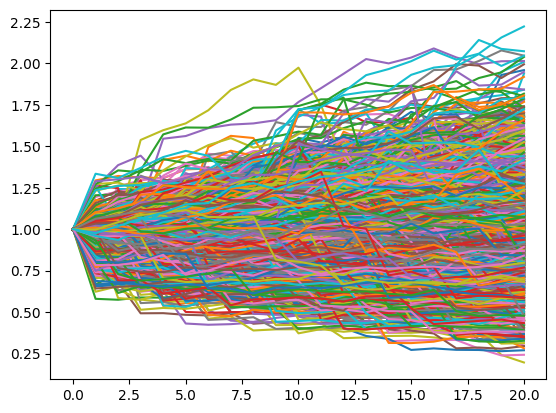

Time indices:
 [0, 0.05, 0.1, 0.15000000000000002, 0.2, 0.25, 0.30000000000000004, 0.35000000000000003, 0.4, 0.45, 0.5, 0.55, 0.6000000000000001, 0.65, 0.7000000000000001, 0.75, 0.8, 0.8500000000000001, 0.9, 0.9500000000000001, 1.0]


In [34]:
#### SIMULATE STOCK PATHS TO COMPUTE THE QUANTILES ####
if __name__ == "__main__" : 
    Nsim = 5000
    Nsteps = timepoints * 10
    delta_t = 1/Nsteps

    stock_paths = np.zeros([Nsim,Nsteps+1])
    stock_paths[:,0] = stock
    np.random.seed(2)
    

    time_indices = [] # list to store the corresponding time-points at which the stock paths are beong calculated
    time_indices.append(0)

    Z1 = np.random.normal(size=[Nsim,Nsteps])
    Z2 = np.random.normal(size=[Nsim,Nsteps])
    Poisson = np.random.poisson(lmda*delta_t, [Nsim,Nsteps])
    In = []

    for i in range(Nsteps):
        stock_paths[:,i+1] = stock_paths[:,i] * np.exp((r-div-lmda * g - 0.5 * sigma **2)*delta_t \
         + sigma * np.sqrt(delta_t) * Z1[:,i] + mu_j * Poisson[:,i] +\
                                                   np.sqrt(Poisson[:,i]) * sigma_j *Z2[:,i])
        time_indices.append(delta_t * (i + 1))
    
    
    index1 = time_indices.index(T_GRID[1]) #index corresponding to short maturity
    index2 = time_indices.index(T) #index corresponding to target maturity

    print(f"Index corresponding to short maturity {time_indices[index1]} :{index1}")
    
    print(f"Index corresponding to target maturity {time_indices[index2]} :{index2}")
    
    #plot the stock paths
    t_paths = np.linspace(0, Nsteps, Nsteps+1)
    plt.plot(t_paths,stock_paths.transpose())
    plt.show()
    plt.close()
    
    #print the intermediate time points
    print(f"Time indices:\n {time_indices}")
    

In [35]:
## GET QUANTILES AT THE SHORT MATURITY AND TARGET MATURITY 

def hedge_payoff_intermediate_time(stock_value,time_point,weights,short_strikes):
    """
     Computes the payoff of the hedge portfolio at intermediate time-points(<= short_maturity) 
    """
    if time_point < T_GRID[1]: # if time_point < short-maturity
        
        payoff_arrays =  [weights[l+1] * MJD_call(stock_value, short_strikes[l], time_point,
                                                                    T_GRID[1], sigma, r,lmda, g, mu_j, sigma_j, div)
                           
                          for l in range(len(short_strikes))]#creates a list of dimension Nsim x len(short_strikes)
        payoff_hedge =  weights[0] + np.sum(payoff_arrays, axis = 0)
            
        
        
    if time_point == T_GRID[1]: # if time_point =  short maturity
        payoff_arrays = [weights[l+1] * np.maximum(stock_value - short_strikes[l],0)
                                            for l in range(len(short_strikes))]   
        payoff_hedge =  weights[0] + np.sum(payoff_arrays, axis = 0)
        
    return payoff_hedge
            


In [36]:
def target_payoff_intermediate_time(stock_value,time_point,T_GRID,target_strike):
    """
     Computes the payoff of the target option at intermediate time-points(less than or equal to the target maturity) 
     """
    target_value = np.empty_like(stock_value)
    
    if time_point < T_GRID[1]:# if time_point < short_maturity
        
        #first simulate the stock_paths at the short_maturity and T given the current stock price
        np.random.seed(5)
        N_sim_2 = 5000
        N_steps_2 = 2
        
        
        Z_normal = np.random.normal(size=[N_sim_2,N_steps_2])
        Z2_normal = np.random.normal(size=[N_sim_2,N_steps_2])
        
        #time left to short maturity
        delta_t1 = T_GRID[1] - time_point
        Poisson1 = np.random.poisson(lmda*delta_t1, [N_sim_2])
        
        
        stock_paths_initial = stock_value * np.ones(N_sim_2)
        
        #compute the stock prices at short maturity
       
        stock_paths_T1 = stock_paths_initial * np.exp((r-div-lmda * g - 0.5 * sigma **2)*delta_t1 \
         + sigma * np.sqrt(delta_t1) * Z_normal[:,0] + mu_j * Poisson1[:] +\
                                                   np.sqrt(Poisson1[:]) * sigma_j *Z2_normal[:,0])
      
        
        #time difference between short maturity and target maturity
        delta_t2 = T_GRID[2] - T_GRID[1]
        Poisson2 = np.random.poisson(lmda*delta_t2, [N_sim_2])
        
        
        #compute the stock prices at target maturity
        stock_paths_T = stock_paths_T1 * np.exp((r-div-lmda * g - 0.5 * sigma **2)*delta_t2 \
         + sigma * np.sqrt(delta_t2) * Z_normal[:,1] + mu_j * Poisson2[:] +\
                                                   np.sqrt(Poisson2[:]) * sigma_j *Z2_normal[:,1])
      
        #compute the means
#         print(f"Average of the stock price values:{np.mean(stock_paths_T1),np.mean(stock_paths_T)}")
        
        #compute the payoff at maturity for the stock price paths
        target_value = np.mean(Asian_option_payoff(stock_paths_T1, stock_paths_T,target_strike) 
                              ) 
    elif time_point == T_GRID[1]: # if time_point = short_maturity
        
        target_value = MJD_call(stock_value, stock_value, T_GRID[1], T, sigma, r, lmda, g, mu_j, sigma_j, div)
    
    return target_value
    





In [37]:
def objective_value_for_stock_paths(time_point,stock_price_values, optimal_weights,T_GRID,K,short_strikes):
    """
    Compute the objective value for the stock price paths at a given time-point
    """
    
    
    
#     print(f"The short strikes are:{short_strikes}")
    
    objective_value = (target_payoff_intermediate_time(stock_price_values ,time_point,T_GRID,K) - 
           hedge_payoff_intermediate_time(stock_price_values, time_point, optimal_weights, short_strikes)
                      )

    return objective_value


In [38]:
def l_2_norm(x):
    """
    Compute the l_2_norm of a vector x
    """
    sum_of_squares = 0
    for i in x:
        sum_of_squares += i**2
    norm = np.sqrt(sum_of_squares)
    return norm

**EXPERIMENT 1: Run the minimization algorithm without bounds on weights**

In [71]:
with open('Data_max_min_MJD_Forward.pkl','rb') as f:
    data_max_min = pickle.load(f)

In [40]:
Weights_maxmin_list = data_max_min['Weights_opt_list']

In [41]:
data_max_min['Objective_value_list']

[-0.04657647603171564,
 -0.045424556871822286,
 -0.04373448919168447,
 -0.03167403002306717,
 -0.036642104617853534,
 -0.0365365879196667,
 -0.034751989870980965,
 -0.034825953773798365,
 -0.023020882363799153,
 -0.0003524706584785353,
 -0.0,
 -0.0]

In [42]:
if __name__ == "__main__":

    M_bound = 10
   
    
    
    list_of_weights = []
    list_of_objectives = []
    list_of_dictionaries = []
    list_of_pmatrix = []
    
    for weights in Weights_maxmin_list:
        x0 = weights #set initial weights as the one from maxmin
    
        no_of_options = len(x0)-1
        short_strikes = short_strike_range[:no_of_options] 


        result_data_no_bounds = run_experiment_no_M(M_bound=M_bound,
            solver="gurobi",
            truncation_range=truncation_range,
            N=N,
            no_of_options=no_of_options,
            short_strikes=short_strikes,
            epsilon= 0,
            choice="non-uniform",
            x0 = x0#[0]*(no_of_options+1)
        )

        diff = 5
        previous_opt_value = result_data_no_bounds['final_value']

        while abs(diff)>1e-4:
            result_data_no_bounds = run_experiment_no_M(M_bound=M_bound,
            solver="gurobi",
            truncation_range=truncation_range,
            N=N,
            no_of_options=no_of_options,
            short_strikes=short_strikes,
            epsilon= 0,
            choice="non-uniform",
            x0 = x0#[0]*(no_of_options+1)

        )
            diff = result_data_no_bounds['final_value'] - previous_opt_value
            x0 = result_data_no_bounds['w_opt']
            previous_opt_value = result_data_no_bounds['final_value'] 

        # Make a similar dictionary
        run_dict_no_bounds = {
            "Solver": "gurobi",
            "M_coeff": "No_M",   # or 0, or None—some label
            "Truncation_range": truncation_range,
            "N_initial": result_data_no_bounds["N_initial"],
            "N": result_data_no_bounds["N"],
            "no_of_options": no_of_options,
            "epsilon": 0.0,
            "M_bound": M_bound,
            "Optimal_weights": result_data_no_bounds["w_opt"],
             "Final_value": result_data_no_bounds["final_value"],
             "P_matrix": result_data_no_bounds["p_matrix"],
            "Target_price": result_data_no_bounds["target_call_price"],
            "Hedge_value": result_data_no_bounds["hedge_value"]
         }
        print(f"========== Experiment Complete ==========")

        print("Optimal Weights:", result_data_no_bounds["w_opt"])
        print("Final Value from min-max:", result_data_no_bounds["final_value"])

        
#         current_objective = result_data_no_bounds["final_value"]
        
        
#         if i == 0:
#             previous_objective = current_objective
#             previous_dictionary = run_dict_no_M
#         else:    
#             if current_objective <= previous_objective:
#                 previous_objective = current_objective
#                 previous_dictionary = run_dict_no_M
            
        list_of_weights.append( result_data_no_bounds["w_opt"])
        list_of_objectives.append(result_data_no_bounds["final_value"])
        list_of_pmatrix.append(result_data_no_bounds['p_matrix'])
        list_of_dictionaries.append( run_dict_no_bounds)

The strike for time 0.5 is 2.0014684065646935 and interpolated call value: 6.818615225397118e-20
The strike for time 1 is 2.006797239097272 and interpolated call value: -2.2497195079074217e-18
The new discretization points are:[[0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
  1.00071779 1.03394153 1.06621802 1.10544    1.40205472 2.00146841]
 [0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
  1.00071779 1.03394153 1.06621802 1.10544    1.40205472 2.00679724]]
Number of discretization points are:12
timepoint: 0.5
12
Sum of marginals at 0.5 is: 1.0
timepoint: 1
12
Sum of marginals at 1 is: 0.9999999999999999
Short strikes: [0.]
Short call value 0 is: 1.0
length of short_call 1
value from gurobi:0.06731112107547815
val solving max LP:0.06731112107547672

value from gurobi:0.06795680422711206
val solving max LP:0.06795680422711302

value from gurobi:0.06715205286438164
val solving max LP:0.06715205286438353

value from gurobi:0.06848092531042414
val so

value from gurobi:0.06848092531042414
val solving max LP:0.06848092531042342

value from gurobi:0.06758881944681491
val solving max LP:0.06758876199980136

value from gurobi:0.06724517438252245
val solving max LP:0.06724517438252427

value from gurobi:0.06952387755359574
val solving max LP:0.06952387755359432

value from gurobi:0.06715143219304916
val solving max LP:0.0671513840178961

value from gurobi:0.06742909373692346
val solving max LP:0.06742909373692378

value from gurobi:0.06700784427487587
val solving max LP:0.06700784427487488

value from gurobi:0.06701777266501806
val solving max LP:0.06701777266502032

value from gurobi:0.06687123486141308
val solving max LP:0.06687123486141158

value from gurobi:0.0670145539924924
val solving max LP:0.06701455399249234

value from gurobi:0.0678028198207924
val solving max LP:0.06780276688839956

value from gurobi:0.06697393453087781
val solving max LP:0.06697389066356702

value from gurobi:0.0668403064819155
val solving max LP:0.066840262

value from gurobi:0.06144720505416916
val solving max LP:0.061447163243431246

value from gurobi:0.06129283502928677
val solving max LP:0.06129279321854751

value from gurobi:0.06280864729891827
val solving max LP:0.06280864729891732

value from gurobi:0.061662399143948866
val solving max LP:0.061662399143947125

value from gurobi:0.06549177398754155
val solving max LP:0.06549177398754186

value from gurobi:0.061175559720753996
val solving max LP:0.061175559720754856

value from gurobi:0.061654201884756274
val solving max LP:0.061654201884759285

value from gurobi:0.06110727536369373
val solving max LP:0.061107275363694265

value from gurobi:0.06110621161435732
val solving max LP:0.06110621161435863

value from gurobi:0.06147017181882708
val solving max LP:0.06147017181882751

value from gurobi:0.06227191809911186
val solving max LP:0.06227191809911433

value from gurobi:0.061172250019257024
val solving max LP:0.06117220820851934

value from gurobi:0.06098997905609127
val solving max L

value from gurobi:0.058060893643902316
val solving max LP:0.05806089364390205

value from gurobi:0.05806079427509071
val solving max LP:0.058060794275092226

value from gurobi:0.05806073678076203
val solving max LP:0.05806073678076278

value from gurobi:0.058060664152302814
val solving max LP:0.058060620284992086

Optimization terminated successfully.
         Current function value: 0.058061
         Iterations: 67
         Function evaluations: 122
Optimization terminated successfully.
Constraint violations found at the final solution:
  - Row sum constraint violated at i=7: LHS=0.07904714255963297, RHS=0.07904718765091484
  - Row sum constraint violated at i=11: LHS=0.001612184368060214, RHS=0.0016121031720037885
  - Column sum constraint violated at j=8: LHS=0.05321717986545001, RHS=0.0532170986693935
  - Column sum constraint violated at j=11: LHS=0.013265268607410275, RHS=0.013265313698692143
  - Martingale constraint violated at i=7: LHS=-4.386731101459207e-08
  - Martingale con

value from gurobi:0.05807838348424146
val solving max LP:0.05807838348424097

value from gurobi:0.05806867059714545
val solving max LP:0.05806867059714394

value from gurobi:0.05806385832450456
val solving max LP:0.058063858324504794

value from gurobi:0.05807060815397458
val solving max LP:0.05807060815397256

value from gurobi:0.05806458882975836
val solving max LP:0.0580645888297597

value from gurobi:0.058066464540396066
val solving max LP:0.058066464540393346

value from gurobi:0.058062803426691165
val solving max LP:0.058062803426689444

value from gurobi:0.05806242329694005
val solving max LP:0.05806242329694096

value from gurobi:0.058064717848726854
val solving max LP:0.05806471784872876

value from gurobi:0.058061526449131595
val solving max LP:0.05806148899044974

value from gurobi:0.05806453096992979
val solving max LP:0.05806453096993075

value from gurobi:0.05806235776485807
val solving max LP:0.058062357764856805

value from gurobi:0.058062205021820204
val solving max LP

...

value from gurobi:0.05797535196910047
val solving max LP:0.057971254308413225

value from gurobi:0.0579705821302562
val solving max LP:0.05797054467157135

value from gurobi:0.0579750000272195
val solving max LP:0.05797090210193475

value from gurobi:0.057970160222236784
val solving max LP:0.05797016022223803

value from gurobi:0.05796998423538284
val solving max LP:0.0579699467767009

value from gurobi:0.05796909681530192
val solving max LP:0.05796909681530177

value from gurobi:0.057973646572194656
val solving max LP:0.057969548618758304

value from gurobi:0.057973247860191986
val solving max LP:0.057969149620324525

value from gurobi:0.05796878768136232
val solving max LP:0.05796878768136133

value from gurobi:0.057967048580475036
val solving max LP:0.05796704858047498

value from gurobi:0.05796972682777015
val solving max LP:0.057969726827770886

value from gurobi:0.05796835444807236
val solving max LP:0.0579683544480727

value from gurobi:0.05797223287503213
val solving max LP:0.0

value from gurobi:0.05793574162026769
val solving max LP:0.05793574162026738

value from gurobi:0.05795603461702137
val solving max LP:0.05795603461702189

value from gurobi:0.057938385328443295
val solving max LP:0.057938385328443386

value from gurobi:0.05793488521964715
val solving max LP:0.05793488521964789

value from gurobi:0.05793262575513068
val solving max LP:0.057932625755128274

value from gurobi:0.057934004417687826
val solving max LP:0.05793400441768939

value from gurobi:0.057937257639509146
val solving max LP:0.05793725763950884

value from gurobi:0.05793572393678134
val solving max LP:0.057935723936781446

value from gurobi:0.05794456776361972
val solving max LP:0.057944567763620884

value from gurobi:0.05793691022048229
val solving max LP:0.0579369102204834

value from gurobi:0.05793264635337859
val solving max LP:0.05793264635337942

value from gurobi:0.05793237198572315
val solving max LP:0.057932371985721966

value from gurobi:0.057929774884495945
val solving max LP

value from gurobi:0.05792398492186898
val solving max LP:0.05792398492186838

value from gurobi:0.057924213313289424
val solving max LP:0.05792421331328765

value from gurobi:0.05792380864889725
val solving max LP:0.057923808648895576

value from gurobi:0.0579243672387875
val solving max LP:0.057924367238787

value from gurobi:0.057923747252385104
val solving max LP:0.05792374725238568

value from gurobi:0.0579242668362276
val solving max LP:0.0579242668362283

value from gurobi:0.05792349765172878
val solving max LP:0.057923497651728315

value from gurobi:0.05792355144797173
val solving max LP:0.05792355144797152

value from gurobi:0.057924488478566065
val solving max LP:0.057924488478565246

value from gurobi:0.057922886776141366
val solving max LP:0.05792288677614381

value from gurobi:0.05792394519752624
val solving max LP:0.05792394519752595

value from gurobi:0.05792423838261616
val solving max LP:0.057924238382616976

value from gurobi:0.057923700958879075
val solving max LP:0.0

value from gurobi:0.05792288068592168
val solving max LP:0.0579228806859234

value from gurobi:0.05792295285104752
val solving max LP:0.05792295285104714

value from gurobi:0.057922813811577906
val solving max LP:0.057922813811577725

value from gurobi:0.05792303662247947
val solving max LP:0.05792303662247797

value from gurobi:0.057922868622910836
val solving max LP:0.05792286862290918

value from gurobi:0.05792290769087414
val solving max LP:0.05792290769087276

value from gurobi:0.057922959293250316
val solving max LP:0.05792295929325026

value from gurobi:0.0579228684169632
val solving max LP:0.05792286841696346

value from gurobi:0.057922908815461464
val solving max LP:0.0579229088154626

value from gurobi:0.05792286766669067
val solving max LP:0.05792286766669179

value from gurobi:0.05792290223404126
val solving max LP:0.05792290223404084

value from gurobi:0.057922982595717785
val solving max LP:0.057922982595715475

value from gurobi:0.05792285832781581
val solving max LP:0.0

value from gurobi:0.057922807208272996
val solving max LP:0.05792280720827169

value from gurobi:0.05792281295765705
val solving max LP:0.057922812957655716

value from gurobi:0.05792280663266766
val solving max LP:0.05792280663266644

value from gurobi:0.057922811385639816
val solving max LP:0.057922811385639456

value from gurobi:0.05792280446213973
val solving max LP:0.05792280446213921

value from gurobi:0.0579228129986425
val solving max LP:0.05792281299864315

value from gurobi:0.05792280619002374
val solving max LP:0.057922806190022796

value from gurobi:0.057922816498317195
val solving max LP:0.05792281649831695

value from gurobi:0.0579228057649524
val solving max LP:0.05792280576495359

value from gurobi:0.05792280708716317
val solving max LP:0.05792280708716512

value from gurobi:0.05792281334609389
val solving max LP:0.057922813346092

value from gurobi:0.05792280539679281
val solving max LP:0.05792280539679417

value from gurobi:0.057922808605155
val solving max LP:0.05792

In [73]:
Modified_weights_maxmin_list = data_max_min['Modified_weights_list']
print(Modified_weights_maxmin_list[::-1])

[array([ 0.        ,  0.11643283, -1.14097038,  0.90495023,  0.22576808,
        0.08577404, -0.07647914, -0.07238354, -0.00712327,  0.02888167,
       -0.05925134, -0.12772372,  0.        ]), array([ 0.        ,  0.11643283, -1.14097038,  0.90495023,  0.22576808,
        0.08577404, -0.07647914, -0.07238354, -0.00712327,  0.02888167,
       -0.05925134, -0.12772372]), array([ 0.        ,  0.07097104,  0.76915846, -1.09178254,  0.25516214,
        0.34070656,  0.32993186, -0.16516892,  0.2177147 , -3.80520237,
        3.32114142]), array([ 0.00000000e+00,  7.26635910e-06,  4.34183264e-01, -1.67989521e-01,
       -4.92101311e-01,  5.62120113e-01, -2.19055486e+00,  2.51121569e+00,
       -1.95636748e+00,  1.27863776e+00]), array([ 0.00000000e+00,  6.26190194e-11,  1.37465309e-01, -1.75211228e-02,
       -1.87348637e-01,  1.23570603e-01, -3.43125317e-01, -4.08261819e-01,
        9.14393488e-01]), array([ 0.00000000e+00,  6.26190194e-11,  1.37465309e-01, -1.75211228e-02,
       -1.87348637

In [74]:
if __name__ == "__main__":

    M_bound = 10
   
    
    
    modified_list_of_weights = []
    modified_list_of_objectives = []
    modified_list_of_dictionaries = []
    modified_list_of_pmatrix = []
    
    for weights in Modified_weights_maxmin_list:
        x0 = weights #set initial weights as the one from maxmin
    
        no_of_options = len(x0)-1
        short_strikes = short_strike_range[:no_of_options] 


        result_data_no_bounds = run_experiment_no_M(M_bound=M_bound,
            solver="gurobi",
            truncation_range=truncation_range,
            N=N,
            no_of_options=no_of_options,
            short_strikes=short_strikes,
            epsilon= 0,
            choice="non-uniform",
            x0 = x0#[0]*(no_of_options+1)
        )

        diff = 5
        previous_opt_value = result_data_no_bounds['final_value']

        while abs(diff)>1e-4:
            result_data_no_bounds = run_experiment_no_M(M_bound=M_bound,
            solver="gurobi",
            truncation_range=truncation_range,
            N=N,
            no_of_options=no_of_options,
            short_strikes=short_strikes,
            epsilon= 0,
            choice="non-uniform",
            x0 = x0#[0]*(no_of_options+1)

        )
            diff = result_data_no_bounds['final_value'] - previous_opt_value
            x0 = result_data_no_bounds['w_opt']
            previous_opt_value = result_data_no_bounds['final_value'] 

        # Make a similar dictionary
        run_dict_no_bounds = {
            "Solver": "gurobi",
            "M_coeff": "No_M",   # or 0, or None—some label
            "Truncation_range": truncation_range,
            "N_initial": result_data_no_bounds["N_initial"],
            "N": result_data_no_bounds["N"],
            "no_of_options": no_of_options,
            "epsilon": 0.0,
            "M_bound": M_bound,
            "Optimal_weights": result_data_no_bounds["w_opt"],
             "Final_value": result_data_no_bounds["final_value"],
             "P_matrix": result_data_no_bounds["p_matrix"],
            "Target_price": result_data_no_bounds["target_call_price"],
            "Hedge_value": result_data_no_bounds["hedge_value"]
         }
        print(f"========== Experiment Complete ==========")

        print("Optimal Weights:", result_data_no_bounds["w_opt"])
        print("Final Value from min-max:", result_data_no_bounds["final_value"])

        
#         current_objective = result_data_no_bounds["final_value"]
        
        
#         if i == 0:
#             previous_objective = current_objective
#             previous_dictionary = run_dict_no_M
#         else:    
#             if current_objective <= previous_objective:
#                 previous_objective = current_objective
#                 previous_dictionary = run_dict_no_M
            
        modified_list_of_weights.append( result_data_no_bounds["w_opt"])
        modified_list_of_objectives.append(result_data_no_bounds["final_value"])
        modified_list_of_pmatrix.append(result_data_no_bounds['p_matrix'])
        modified_list_of_dictionaries.append( run_dict_no_bounds)

The strike for time 0.5 is 2.0014684065646935 and interpolated call value: 6.818615225397118e-20
The strike for time 1 is 2.006797239097272 and interpolated call value: -2.2497195079074217e-18
The new discretization points are:[[0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
  1.00071779 1.03394153 1.06621802 1.10544    1.40205472 2.00146841]
 [0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
  1.00071779 1.03394153 1.06621802 1.10544    1.40205472 2.00679724]]
Number of discretization points are:12
timepoint: 0.5
12
Sum of marginals at 0.5 is: 1.0
timepoint: 1
12
Sum of marginals at 1 is: 0.9999999999999999
Short strikes: [0.]
Short call value 0 is: 1.0
length of short_call 1
value from gurobi:0.06731112107547815
val solving max LP:0.06731112107547672

value from gurobi:0.06795680422711206
val solving max LP:0.06795680422711302

value from gurobi:0.06715205286438164
val solving max LP:0.06715205286438353

value from gurobi:0.06848092531042414
val so

value from gurobi:0.06848092531042414
val solving max LP:0.06848092531042342

value from gurobi:0.06758881944681491
val solving max LP:0.06758876199980136

value from gurobi:0.06724517438252245
val solving max LP:0.06724517438252427

value from gurobi:0.06952387755359574
val solving max LP:0.06952387755359432

value from gurobi:0.06715143219304916
val solving max LP:0.0671513840178961

value from gurobi:0.06742909373692346
val solving max LP:0.06742909373692378

value from gurobi:0.06700784427487587
val solving max LP:0.06700784427487488

value from gurobi:0.06701777266501806
val solving max LP:0.06701777266502032

value from gurobi:0.06687123486141308
val solving max LP:0.06687123486141158

value from gurobi:0.0670145539924924
val solving max LP:0.06701455399249234

value from gurobi:0.0678028198207924
val solving max LP:0.06780276688839956

value from gurobi:0.06697393453087781
val solving max LP:0.06697389066356702

value from gurobi:0.0668403064819155
val solving max LP:0.066840262

value from gurobi:0.06129283502928677
val solving max LP:0.06129279321854751

value from gurobi:0.06280864729891827
val solving max LP:0.06280864729891732

value from gurobi:0.061662399143948866
val solving max LP:0.061662399143947125

value from gurobi:0.06549177398754155
val solving max LP:0.06549177398754186

value from gurobi:0.061175559720753996
val solving max LP:0.061175559720754856

value from gurobi:0.061654201884756274
val solving max LP:0.061654201884759285

value from gurobi:0.06110727536369373
val solving max LP:0.061107275363694265

value from gurobi:0.06110621161435732
val solving max LP:0.06110621161435863

value from gurobi:0.06147017181882708
val solving max LP:0.06147017181882751

value from gurobi:0.06227191809911186
val solving max LP:0.06227191809911433

value from gurobi:0.061172250019257024
val solving max LP:0.06117220820851934

value from gurobi:0.06098997905609127
val solving max LP:0.060989979056091465

value from gurobi:0.060916513468742245
val solving max 

value from gurobi:0.058060664152302814
val solving max LP:0.058060620284992086

Optimization terminated successfully.
         Current function value: 0.058061
         Iterations: 67
         Function evaluations: 122
Optimization terminated successfully.
Constraint violations found at the final solution:
  - Row sum constraint violated at i=7: LHS=0.07904714255963297, RHS=0.07904718765091484
  - Row sum constraint violated at i=11: LHS=0.001612184368060214, RHS=0.0016121031720037885
  - Column sum constraint violated at j=8: LHS=0.05321717986545001, RHS=0.0532170986693935
  - Column sum constraint violated at j=11: LHS=0.013265268607410275, RHS=0.013265313698692143
  - Martingale constraint violated at i=7: LHS=-4.386731101459207e-08
  - Martingale constraint violated at i=11: LHS=-7.593864351921858e-08
  - Absolute-value constraint with M*B[i] violated at i=7: lhs_3=0.009295182806543316,B[i]=-0.0, P_slack[i]=0.009295226673854332
  - hedging_error:0.009295182806543316, M*B[i]:-0.0. M

value from gurobi:0.05807060815397458
val solving max LP:0.05807060815397256

value from gurobi:0.05806458882975836
val solving max LP:0.0580645888297597

value from gurobi:0.058066464540396066
val solving max LP:0.058066464540393346

value from gurobi:0.058062803426691165
val solving max LP:0.058062803426689444

value from gurobi:0.05806242329694005
val solving max LP:0.05806242329694096

value from gurobi:0.058064717848726854
val solving max LP:0.05806471784872876

value from gurobi:0.058061526449131595
val solving max LP:0.05806148899044974

value from gurobi:0.05806453096992979
val solving max LP:0.05806453096993075

value from gurobi:0.05806235776485807
val solving max LP:0.058062357764856805

value from gurobi:0.058062205021820204
val solving max LP:0.05806220502181935

value from gurobi:0.05806197496827163
val solving max LP:0.058061974968270896

value from gurobi:0.058061360618056536
val solving max LP:0.058061320188033394

value from gurobi:0.05806531605055927
val solving max 

...

value from gurobi:0.05794869607519653
val solving max LP:0.05794865861651417

value from gurobi:0.057947807511127714
val solving max LP:0.05794777005244471

value from gurobi:0.05794710806407034
val solving max LP:0.05794710806407173

value from gurobi:0.05794919386082731
val solving max LP:0.05794919386082757

value from gurobi:0.0579488832722676
val solving max LP:0.05794884581358266

value from gurobi:0.057947070352318636
val solving max LP:0.05794707035231889

value from gurobi:0.05794569083914983
val solving max LP:0.05794565338046652

value from gurobi:0.05794759698020719
val solving max LP:0.057947596980206566

value from gurobi:0.057948405868296665
val solving max LP:0.05794840586829609

value from gurobi:0.05794739192077025
val solving max LP:0.05794739192076913

value from gurobi:0.05794810291294467
val solving max LP:0.05794806545426474

value from gurobi:0.05794714480793152
val solving max LP:0.05794714480792931

value from gurobi:0.0579481074346619
val solving max LP:0.057

value from gurobi:0.057925043970780035
val solving max LP:0.05792504397078125

value from gurobi:0.057924356066055185
val solving max LP:0.057924356066055865

value from gurobi:0.05792574890445383
val solving max LP:0.05792574890445169

value from gurobi:0.05792908247891891
val solving max LP:0.05792908247891611

value from gurobi:0.057923753464842354
val solving max LP:0.057923753464842985

value from gurobi:0.057928837888992495
val solving max LP:0.05792883788899246

value from gurobi:0.05792556349102761
val solving max LP:0.05792556349103019

value from gurobi:0.05792849478717131
val solving max LP:0.0579284947871726

value from gurobi:0.057925705176400145
val solving max LP:0.05792570517640286

value from gurobi:0.05792799648596346
val solving max LP:0.057927996485961655

value from gurobi:0.05792547854251605
val solving max LP:0.05792547854251673

value from gurobi:0.05792891901833406
val solving max LP:0.05792891901833469

value from gurobi:0.057925270259996
val solving max LP:0.

value from gurobi:0.05792284160821687
val solving max LP:0.057922841608216175

value from gurobi:0.057923347665290406
val solving max LP:0.057923347665289324

value from gurobi:0.05792334484793445
val solving max LP:0.05792334484793616

value from gurobi:0.057923207763249565
val solving max LP:0.057923207763249204

value from gurobi:0.05792320263753846
val solving max LP:0.0579232026375379

value from gurobi:0.057924052430720296
val solving max LP:0.05792405243071946

value from gurobi:0.05792309530432176
val solving max LP:0.05792309530431965

value from gurobi:0.05792308776125069
val solving max LP:0.05792308776125281

value from gurobi:0.05792331140713419
val solving max LP:0.0579233114071339

value from gurobi:0.05792359860045771
val solving max LP:0.05792359860045643

value from gurobi:0.057923055358270026
val solving max LP:0.05792305535826987

value from gurobi:0.05792336747002617
val solving max LP:0.057923367470026875

value from gurobi:0.057922968592704606
val solving max LP:

value from gurobi:0.05792282713600493
val solving max LP:0.05792282713600412

value from gurobi:0.05792286556000284
val solving max LP:0.05792286556000345

value from gurobi:0.05792282254034531
val solving max LP:0.05792282254034576

value from gurobi:0.05792284802178941
val solving max LP:0.057922848021787064

value from gurobi:0.05792282515395202
val solving max LP:0.057922825153951994

value from gurobi:0.05792283238423623
val solving max LP:0.0579228323842352

value from gurobi:0.057922846371946494
val solving max LP:0.057922846371945044

value from gurobi:0.05792282556038389
val solving max LP:0.057922825560381294

value from gurobi:0.0579228449160918
val solving max LP:0.05792284491608945

value from gurobi:0.05792282335019342
val solving max LP:0.05792282335019212

value from gurobi:0.057922845548771244
val solving max LP:0.05792284554877088

value from gurobi:0.05792282514310604
val solving max LP:0.057922825143105344

value from gurobi:0.057922837968455376
val solving max LP:0

value from gurobi:0.05792280215991198
val solving max LP:0.05792280215991194

value from gurobi:0.05792280627255031
val solving max LP:0.057922768813868576

value from gurobi:0.05792280687139279
val solving max LP:0.057922806871391605

value from gurobi:0.05792280414656453
val solving max LP:0.05792280414656316

value from gurobi:0.05792280328900902
val solving max LP:0.05792280328900886

value from gurobi:0.057922803807007046
val solving max LP:0.05792280380700711

value from gurobi:0.057922803811225124
val solving max LP:0.05792280381122499

value from gurobi:0.05792280705660986
val solving max LP:0.057922807056608655

value from gurobi:0.057922803660218194
val solving max LP:0.057922803660218854

value from gurobi:0.057922804249076726
val solving max LP:0.057922804249077316

value from gurobi:0.05792280425315871
val solving max LP:0.05792280425315885

value from gurobi:0.05792280430077893
val solving max LP:0.05792280430077892

value from gurobi:0.05792280431960463
val solving max L

In [76]:
 modified_list_of_objectives[::-1]

[np.float64(0.057922768813868576),
 np.float64(0.059185435211229744),
 np.float64(0.0612581747616982),
 np.float64(0.06292739469096063),
 np.float64(0.058702979925342444),
 np.float64(0.05910669118109378),
 np.float64(0.061505534921292286),
 np.float64(0.0582099668140313),
 np.float64(0.05846950111730938),
 np.float64(0.05823517444313623),
 np.float64(0.058060620284992086),
 np.float64(0.05828604504212624)]

In [44]:
list_of_objectives

[np.float64(0.05828604504212624),
 np.float64(0.058060620284992086),
 np.float64(0.05823517444313623),
 np.float64(0.059439461709908305),
 np.float64(0.0582099668140313),
 np.float64(0.061505534921292286),
 np.float64(0.058528693993448955),
 np.float64(0.058702979925342444),
 np.float64(0.06292739469096063),
 np.float64(0.0612581747616982),
 np.float64(0.059185435211229744),
 np.float64(0.057922768813868576)]

In [45]:
#Folder to store the plots
folder_name = 'MJD_Forward_start_JUNE_2025'


Plot for 1 options:



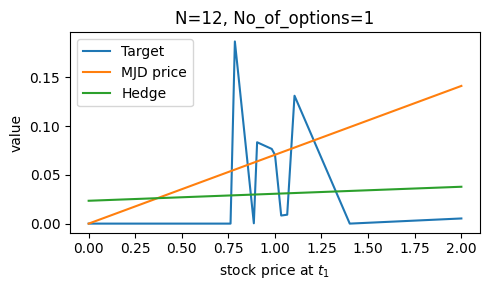

The L2 norm of the difference between true target value and hedge portfolio value is:0.1675236142981584

Plot for 2 options:



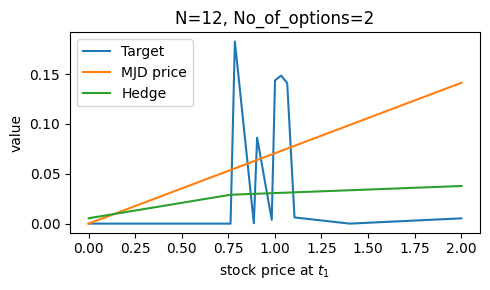

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 3 options:



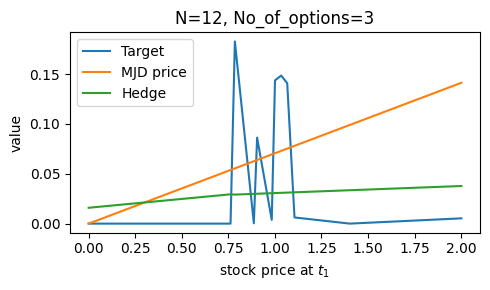

The L2 norm of the difference between true target value and hedge portfolio value is:0.16658803353093618

Plot for 4 options:



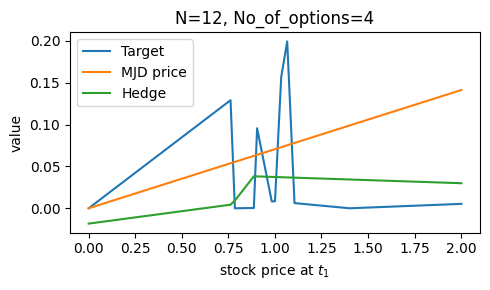

The L2 norm of the difference between true target value and hedge portfolio value is:0.17123341204798567

Plot for 5 options:



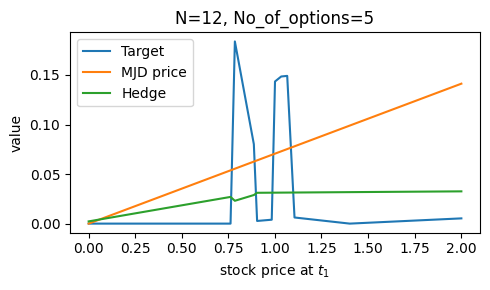

The L2 norm of the difference between true target value and hedge portfolio value is:0.17070840510792218

Plot for 6 options:



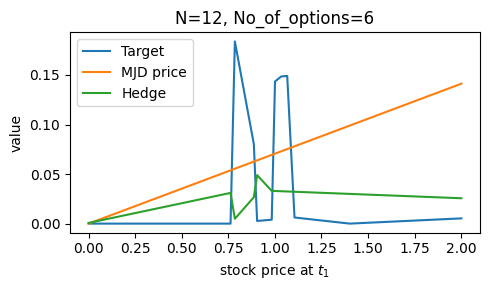

The L2 norm of the difference between true target value and hedge portfolio value is:0.17607165267741798

Plot for 7 options:



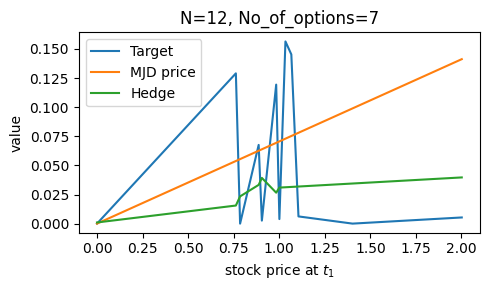

The L2 norm of the difference between true target value and hedge portfolio value is:0.16618454530507387

Plot for 8 options:



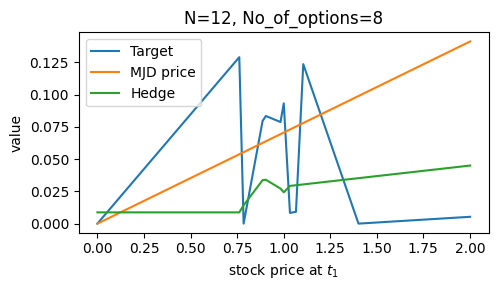

The L2 norm of the difference between true target value and hedge portfolio value is:0.17034124516405483

Plot for 9 options:



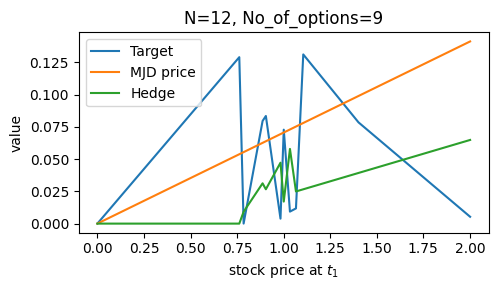

The L2 norm of the difference between true target value and hedge portfolio value is:0.15986984934943174

Plot for 10 options:



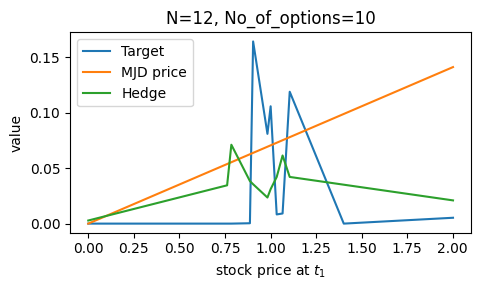

The L2 norm of the difference between true target value and hedge portfolio value is:0.16322548725921976

Plot for 11 options:



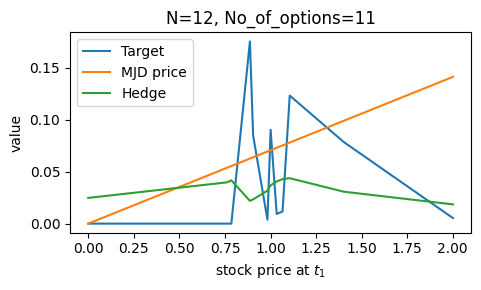

The L2 norm of the difference between true target value and hedge portfolio value is:0.17276333215259307

Plot for 12 options:



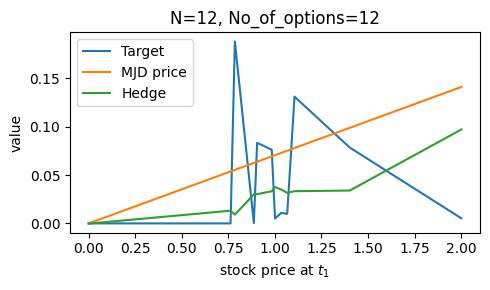

The L2 norm of the difference between true target value and hedge portfolio value is:0.14091993403190717


In [46]:
# #PLOT AND CHECK HOW IT LOOKS
# for idx,weights in enumerate(list_of_weights):

#     Weights_opt_without_bounds = weights
#     P_matrix_no_bounds = list_of_pmatrix[idx]
    
    
#     no_of_options = len(Weights_opt_without_bounds) - 1
#     short_strikes = short_strike_range[:no_of_options]
    
#     print(f"\nPlot for {no_of_options} options:\n")
    
#     plot_one_run( K1,
#         K2,
#         truncation_range,
#         N,
#         Weights_opt_without_bounds,
#         P_matrix_no_bounds,
#         marg,
#         K,
#         T_GRID,
#         sigma,
#         r,
#         lmda, g, mu_j, sigma_j, div,
#         run_idx=None,
#         save=False,
#         folder=folder_name,
#         short_strikes=short_strikes,         
#         fname='Conditional_plot_no_bounds_zoomed_in',
#         show=True,
#         asian_payoff=Asian_option_payoff,
#         MJD_call=MJD_call,

#     )
    

In [47]:
objective_value_full_list_for_weights=[]


for idx, weights in enumerate(list_of_weights):
    Weights_opt_without_bounds = weights#result_data_no_bounds["w_opt"]
    P_matrix_no_bounds = list_of_pmatrix[idx]
    
    
    print(f"\n===Plot for {idx+1} options==\n")
    
    short_strikes = short_strike_range[:len( Weights_opt_without_bounds)-1]
    
    
    print(f"\n Short strikes:{short_strikes}\n")
    
    objective_value_list_intermediate_time_no_bounds = np.zeros((index1+1,Nsim))

    for i in range(index1+1):
            for j in range(len(stock_paths[:,i])):
                 #objective value at the intermediate time points
                objective_value_list_intermediate_time_no_bounds[i,j] = objective_value_for_stock_paths(time_indices[i],
                                                             stock_paths[j,i],
                                                            weights,
                                                             T_GRID,K,
                                                             short_strikes)
     
    objective_value_full_list_for_weights.append(objective_value_list_intermediate_time_no_bounds )  

print("Complete!")


===Plot for 1 options==


 Short strikes:[0.]


===Plot for 2 options==


 Short strikes:[0.         0.76189701]


===Plot for 3 options==


 Short strikes:[0.         0.76189701 0.78513901]


===Plot for 4 options==


 Short strikes:[0.         0.76189701 0.78513901 0.88702254]


===Plot for 5 options==


 Short strikes:[0.         0.76189701 0.78513901 0.88702254 0.90460038]


===Plot for 6 options==


 Short strikes:[0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813]


===Plot for 7 options==


 Short strikes:[0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
 1.00071779]


===Plot for 8 options==


 Short strikes:[0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
 1.00071779 1.03394153]


===Plot for 9 options==


 Short strikes:[0.         0.76189701 0.78513901 0.88702254 0.90460038 0.98316813
 1.00071779 1.03394153 1.06621802]


===Plot for 10 options==


 Short strikes:[0.         0.76189701 0.78513901 0.88702254 0.90460038 0.9831

In [49]:
data_min_max = {"objective_value_sim_full_list_for_weights" : objective_value_full_list_for_weights,
                "list_of_weights":list_of_weights,
                "list_of_dictionaries":list_of_dictionaries,
                "list_of_objectives":list_of_objectives,
                "list_of_pmatrix":list_of_pmatrix}

In [50]:
#Update the set of objective values to store only the minimum value

previous_min = data_min_max['list_of_objectives'][0]
previous_weights = data_min_max['list_of_weights'][0].tolist()
prevous_p_matrix = data_min_max['list_of_pmatrix'][0]
previous_objective_value_simulations = objective_value_full_list_for_weights[0]

new_set_of_obj = []
new_set_of_weights = []
new_set_of_pmatrix = []
new_objective_value_full_list_for_weights = []


for idx,value in enumerate(data_min_max['list_of_objectives']):
    if value<=previous_min:
        new_set_of_obj.append(value)
        new_set_of_weights.append(data_min_max['list_of_weights'][idx].tolist())
        new_set_of_pmatrix.append(data_min_max['list_of_pmatrix'][idx])
        new_objective_value_full_list_for_weights.append(objective_value_full_list_for_weights[idx])
        
    else:
        new_set_of_obj.append(previous_min)
        new_set_of_weights.append(previous_weights+[0])
        new_set_of_pmatrix.append(prevous_p_matrix)
        new_objective_value_full_list_for_weights.append(previous_objective_value_simulations)
    
    previous_min = new_set_of_obj[-1]
    previous_weights = new_set_of_weights[-1]
    prevous_p_matrix = new_set_of_pmatrix[-1]
    previous_objective_value_simulations = new_objective_value_full_list_for_weights[-1] 

In [51]:
#Compute the maximum/peak PFEs with respect to each weight combination till short maturity



peak_PFE_99_list = []
peak_PFE_95_list = []
peak_PFE_5_list = []
peak_PFE_1_list = []
mean_absolute_error_list = []
No_of_options_list = []
    
for idx,element in enumerate(new_objective_value_full_list_for_weights):#get the index and the corresponding element from the list
    
    print(f"The optimal weights for {idx+1} options are:{list_of_weights[idx]}")
    
    #print the shape of the the ith element: should be index1 x Nsim
    print(f"Shape of the {idx}th element:{element.shape}")
    
    #compute the PFEs at each time point till short maturity
    ninety_nine_percentile_list = np.percentile(element,99, axis=1)
    ninety_fifth_percentile_list = np.percentile(element,95,axis=1) 
    fifth_percentile_list = np.percentile(element,5,axis=1)
    first_percentile_list = np.percentile(element,1,axis=1) 
    mean_of_absolute_error = np.mean(np.abs(element),axis=1) 
    
    #compute the peak PFEs
    peak_PFE_99 = np.max(ninety_nine_percentile_list)
    peak_PFE_95 = np.max(ninety_fifth_percentile_list)
    peak_PFE_5 = np.min(fifth_percentile_list)
    peak_PFE_1 = np.min(first_percentile_list)
    peak_mean_absolute_error = mean_of_absolute_error[-1] 
    
    print(f"Peak mean absolute error is: {peak_mean_absolute_error}")
    print(mean_of_absolute_error[-1])
   
    peak_PFE_99_list.append(peak_PFE_99)
    peak_PFE_95_list.append(peak_PFE_95)
    peak_PFE_5_list.append(peak_PFE_5)
    peak_PFE_1_list.append(peak_PFE_1)
    mean_absolute_error_list.append(mean_of_absolute_error[-1])
    
    No_of_options_list.append(len(list_of_weights[idx])-1)

The optimal weights for 1 options are:[0.02342934 0.00718227]
Shape of the 0th element:(11, 5000)
Peak mean absolute error is: 0.03989494305630838
0.03989494305630838
The optimal weights for 2 options are:[ 0.005406    0.03089612 -0.0238241 ]
Shape of the 1th element:(11, 5000)
Peak mean absolute error is: 0.04010847390469418
0.04010847390469418
The optimal weights for 3 options are:[ 0.01589796  0.01770478 -0.02959634  0.01896924]
Shape of the 2th element:(11, 5000)
Peak mean absolute error is: 0.04010847390469418
0.04010847390469418
The optimal weights for 4 options are:[-0.01830013  0.02964809  0.18143413  0.07354185 -0.2920338 ]
Shape of the 3th element:(11, 5000)
Peak mean absolute error is: 0.04010847390469418
0.04010847390469418
The optimal weights for 5 options are:[ 0.00225443  0.03240501 -0.20041811  0.22503274  0.07161434 -0.12731515]
Shape of the 4th element:(11, 5000)
Peak mean absolute error is: 0.04010847390469418
0.04010847390469418
The optimal weights for 6 options are


Plot for 1 options:



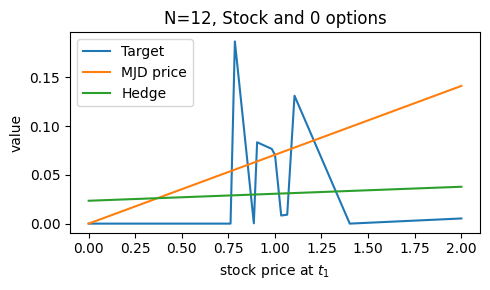

The L2 norm of the difference between true target value and hedge portfolio value is:0.1675236142981584

Plot for 2 options:



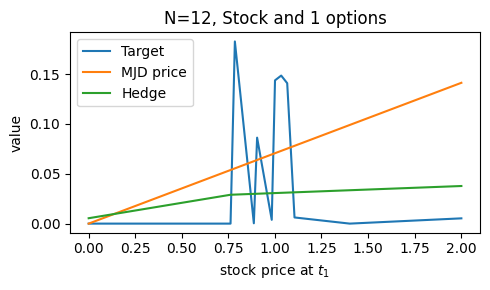

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 3 options:



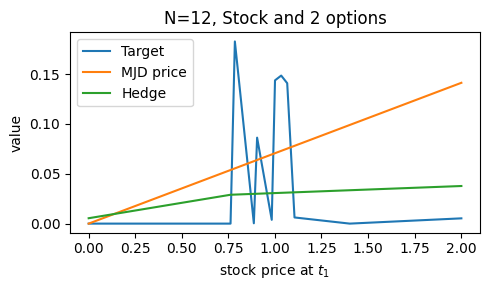

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 4 options:



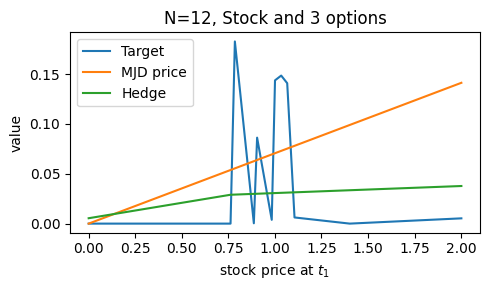

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 5 options:



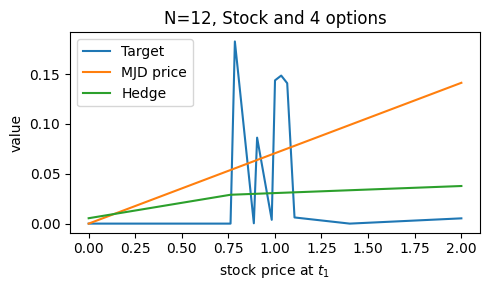

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 6 options:



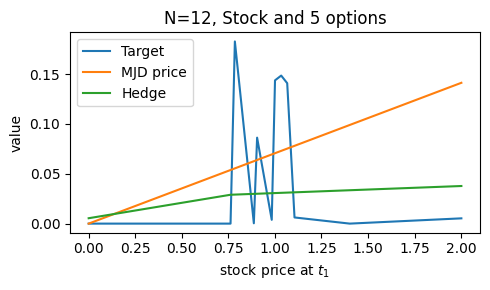

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 7 options:



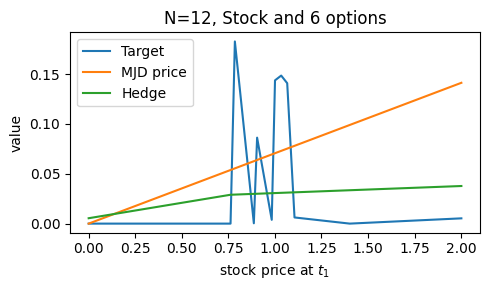

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 8 options:



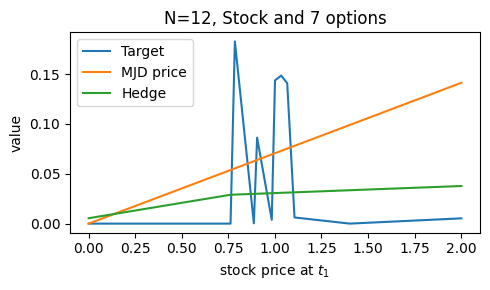

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 9 options:



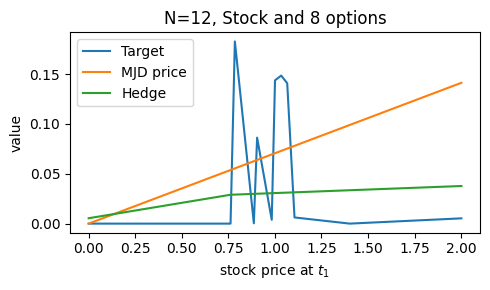

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 10 options:



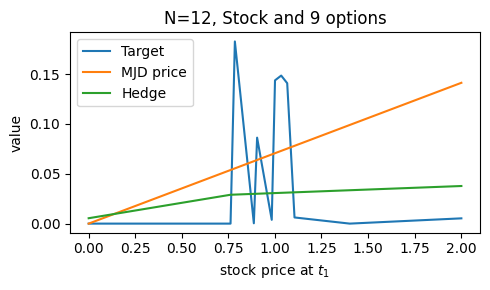

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 11 options:



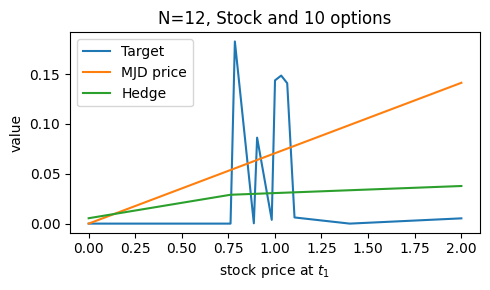

The L2 norm of the difference between true target value and hedge portfolio value is:0.16599113899221216

Plot for 12 options:



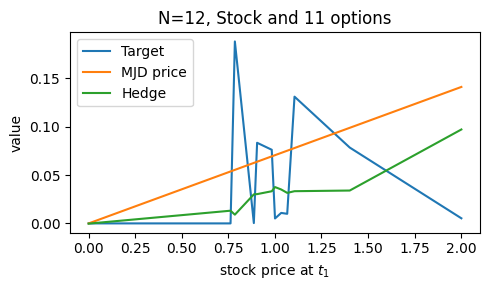

The L2 norm of the difference between true target value and hedge portfolio value is:0.14091993403190717


In [66]:
#PLOT FOR THE  MODIFIED SET OF WEIGHTS
for idx,weights in enumerate(new_set_of_weights):

    Weights_opt_without_bounds = weights
    P_matrix_no_bounds = new_set_of_pmatrix[idx]
    
    
    no_of_options = len(Weights_opt_without_bounds) - 1
    short_strikes = short_strike_range[:no_of_options]
    
    print(f"\nPlot for {no_of_options} options:\n")
    
    plot_one_run( K1,
        K2,
        truncation_range,
        N,
        Weights_opt_without_bounds,
        P_matrix_no_bounds,
        marg,
        K,
        T_GRID,
        sigma,
        r,
        lmda, g, mu_j, sigma_j, div,
        run_idx=None,
        save=True,
        folder=folder_name,
        short_strikes=short_strikes,         
        fname='Conditional_plot_no_bounds_zoomed_in',
        show=True,
        asian_payoff=Asian_option_payoff,
        MJD_call=MJD_call,

    )
    

In [67]:
new_set_of_obj

[np.float64(0.05828604504212624),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.058060620284992086),
 np.float64(0.057922768813868576)]

In [68]:
no_of_options_list2 = [ x-1 for x in No_of_options_list]

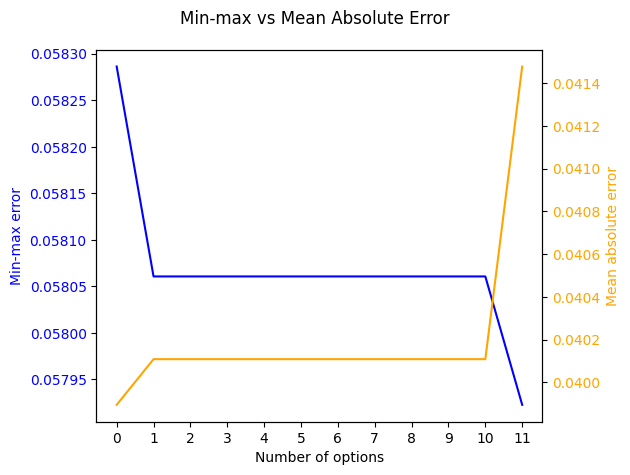

In [69]:




fig, ax1 = plt.subplots()

# First y-axis (left) for min-max
ax1.plot(no_of_options_list2,new_set_of_obj,color='blue', label='min-max')
ax1.set_xlabel('Number of options')
ax1.set_ylabel('Min-max error', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Second y-axis (right) for mean absolute error
ax2 = ax1.twinx()
ax2.plot(no_of_options_list2,mean_absolute_error_list, color = 'orange',label = 'mean absolute error')
ax2.set_ylabel('Mean absolute error', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')
ax1.set_xticks(no_of_options_list2)
# Title and legend
fig.suptitle('Min-max vs Mean Absolute Error')
fig.tight_layout()



# plt.plot(no_of_options_list2,peak_PFE_99_list,label='99th percentile')
# plt.plot(no_of_options_list2,peak_PFE_95_list,label='95th percentile')
# plt.plot(no_of_options_list2,peak_PFE_5_list,label='5th percentile')
# plt.plot(no_of_options_list2,peak_PFE_1_list,label='1st percentile')

# plt.xlabel("Number of options")
# plt.title(f"Peak PFEs till short_maturity {T_GRID[1]}")
# plt.xticks(no_of_options_list2)
# plt.legend()
# plt.show()
# plt.close()




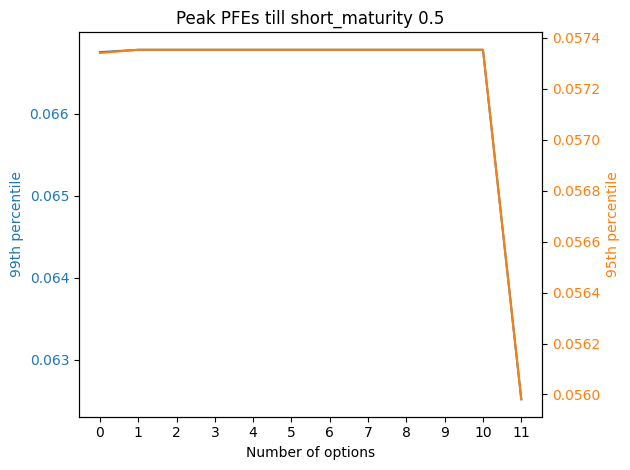

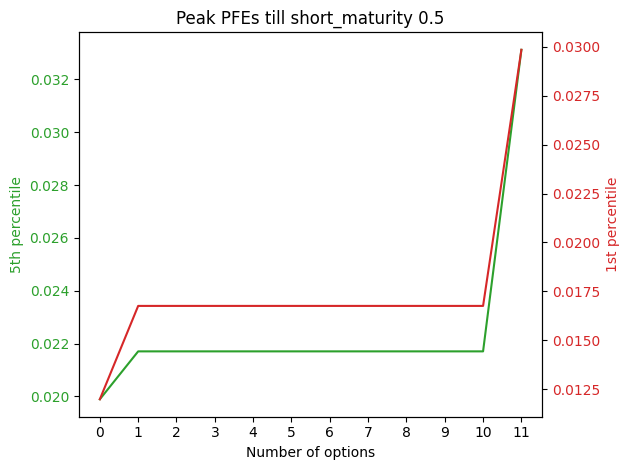

In [70]:
import matplotlib.pyplot as plt

# Example data placeholders
# no_of_options_list2 = [...]
# peak_PFE_99_list = [...]
# peak_PFE_95_list = [...]
# peak_PFE_5_list = [...]
# peak_PFE_1_list = [...]
# T_GRID = [...]  # Make sure T_GRID[1] exists

# --- Plot 1: 99th vs 95th Percentiles ---
fig1, ax1 = plt.subplots()

color1 = 'tab:blue'
ax1.plot(no_of_options_list2, peak_PFE_99_list, color=color1, label='99th percentile')
ax1.set_ylabel('99th percentile', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xlabel('Number of options')
ax1.set_title(f'Peak PFEs till short_maturity {T_GRID[1]}')
ax1.set_xticks(no_of_options_list2)

ax2 = ax1.twinx()
color2 = 'tab:orange'
ax2.plot(no_of_options_list2, peak_PFE_95_list, color=color2, label='95th percentile')
ax2.set_ylabel('95th percentile', color=color2)
ax2.tick_params(axis='y', labelcolor=color2)

fig1.tight_layout()
plt.show()

# --- Plot 2: 5th vs 1st Percentiles ---
fig2, ax3 = plt.subplots()

color3 = 'tab:green'
ax3.plot(no_of_options_list2, peak_PFE_5_list, color=color3, label='5th percentile')
ax3.set_ylabel('5th percentile', color=color3)
ax3.tick_params(axis='y', labelcolor=color3)
ax3.set_xlabel('Number of options')
ax3.set_title(f'Peak PFEs till short_maturity {T_GRID[1]}')
ax3.set_xticks(no_of_options_list2)

ax4 = ax3.twinx()
color4 = 'tab:red'
ax4.plot(no_of_options_list2, peak_PFE_1_list, color=color4, label='1st percentile')
ax4.set_ylabel('1st percentile', color=color4)
ax4.tick_params(axis='y', labelcolor=color4)

fig2.tight_layout()
plt.show()


In [79]:
data_MJD_Forward = {"objective_value_sim_full_list_for_weights" : objective_value_full_list_for_weights,
                   "modified_value_sim_full_list_for_weights" : new_objective_value_full_list_for_weights,
                "list_of_weights":list_of_weights,
                "modified_list_of_weights":new_set_of_weights,
                "old_list_of_dictionaries":list_of_dictionaries,
                "list_of_objectives":list_of_objectives,
                "new_list_of_objectives":new_set_of_obj,
                "list_of_pmatrix":list_of_pmatrix}

In [80]:
# with open('peak_PFE_data_MJD_Forward.pkl','wb') as f:
#     pickle.dump(data_MJD_Forward,f)

**STOP**

**EXPERIMENT 2: Run the minimization algorithm with bounds on weights**

In [ ]:
if __name__ == "__main__":
    bounds = [(-0.1,0.1)]
    
    list_of_objectives = []
    list_of_dictionaries = []
    
#     no_of_options = 4
#     short_strikes = short_strike_range[:no_of_options]
    
    result_data_with_bounds = run_experiment_no_M(solver="gurobi",
        truncation_range=truncation_range,
        N=N,
        no_of_options=no_of_options,
        short_strikes=short_strikes,
        epsilon= 0,
        M_bound= 0,
        choice="non-uniform",
        x0 = [0] *(no_of_options+1 ),
        bounds = bounds * (no_of_options+1 )
    )



    # Make a similar dictionary
    run_dict_with_bounds = {
        "Solver": "gurobi",
        "M_coeff": "No_M",   # or 0, or None—some label
        "Truncation_range": truncation_range,
        "N_initial": result_data_with_bounds["N_initial"],
        "N": result_data_with_bounds["N"],
        "no_of_options": no_of_options,
        "epsilon": 0.0,
        "bounds": bounds,
        "Optimal_weights": result_data_with_bounds["w_opt"],
         "Final_value": result_data_with_bounds["final_value"],
         "P_matrix": result_data_with_bounds["p_matrix"],
        "Target_price": result_data_with_bounds["target_call_price"],
        "Hedge_value": result_data_with_bounds["hedge_value"]
     }
    print(f"========== Experiment Complete ==========")

    print("Optimal Weights:", result_data_with_bounds["w_opt"])
    print("Final Value from min-max:", result_data_with_bounds["final_value"])
        
        


In [ ]:
#PLOT AND CHECK HOW IT LOOKS

Weights_opt_with_bounds = result_data_with_bounds["w_opt"]
P_matrix_with_bounds = result_data_with_bounds["p_matrix"]


plot_one_run( K1,
    K2,
    truncation_range,
    N,
    Weights_opt_with_bounds,
    P_matrix_with_bounds,          
    marg,
    K,
    T_GRID,
    sigma,
    r,
    short_strikes,
    run_idx=None,
    save=False,
    folder=folder_name,
    fname='Conditional_plot_with_bounds_zoomed_in',
    show=True,
    asian_payoff=Asian_option_payoff,
    MJD_call=MJD_call,
    lo = 2,
    hi = -2
)
        
       

In [ ]:
plot_one_run( K1,
    K2,
    truncation_range,
    N,
    Weights_opt_with_bounds,
    P_matrix_with_bounds,          
    marg,
    K,
    T_GRID,
    sigma,
    r,
    short_strikes,
    run_idx=None,
    save=False,
    folder=folder_name,
    fname='Conditional_plot_with_bounds',
    show=True,
    asian_payoff=Asian_option_payoff,
    MJD_call=MJD_call,
)
        

**EXPERIMENT 3: Run the minimization algorithm with ridge regularization term**

In [ ]:
if __name__ == "__main__":
    regularization = "ridge"
    
    list_of_objectives = []
    list_of_dictionaries = []
    
    lmda_reg = 2
    
    result_data_with_ridge = run_experiment_no_M(solver="gurobi",
        truncation_range=truncation_range,
        N=N,
        no_of_options=no_of_options,
        short_strikes=short_strikes,
        epsilon= 0,
        M_bound= 0,
        choice="non-uniform",
        x0 = [0] *(no_of_options+1 ),
        regularization = "ridge",
        lmda_reg = lmda_reg                                       
    )



    # Make a similar dictionary
    run_dict_with_ridge = {
        "Solver": "gurobi",
        "M_coeff": "No_M",   # or 0, or None—some label
        "Truncation_range": truncation_range,
        "N_initial": result_data_with_ridge["N_initial"],
        "N": result_data_with_ridge["N"],
        "no_of_options": no_of_options,
        "epsilon": 0.0,
        "regularization_parameter": lmda_reg,
        "Optimal_weights": result_data_with_ridge["w_opt"],
         "Final_value": result_data_with_ridge["final_value"],
         "P_matrix": result_data_with_ridge["p_matrix"],
        "Target_price": result_data_with_ridge["target_call_price"],
        "Hedge_value": result_data_with_ridge["hedge_value"]
     }
    print(f"========== Experiment Complete ==========")

    print("Optimal Weights:", result_data_with_ridge["w_opt"])
    print("Final Value from min-max:", result_data_with_ridge["final_value"])
        
        


In [ ]:
#PLOT AND CHECK HOW IT LOOKS

Weights_opt_with_ridge = result_data_with_ridge["w_opt"]
P_matrix_with_ridge = result_data_with_ridge["p_matrix"]

plot_one_run( K1,
    K2,
    truncation_range,
    N,
    Weights_opt_with_ridge,
    P_matrix_with_ridge,
    marg,
    K,
    T_GRID,
    sigma,
    r,
    short_strikes,
    run_idx=None,
    save=False,
    folder=folder_name,
    fname='Conditional_plot_with_ridge',
    show=True,
    asian_payoff=Asian_option_payoff,
    MJD_call=MJD_call,         
)

In [ ]:


plot_one_run( K1,
    K2,
    truncation_range,
    N,
    Weights_opt_with_ridge,
    P_matrix_with_ridge,
    marg,
    K,
    T_GRID,
    sigma,
    r,
    short_strikes,
    run_idx=None,
    save=False,
    folder=folder_name,
    fname='Conditional_plot_with_ridge_zoomed_in',
    show=True,
    asian_payoff=Asian_option_payoff,
    MJD_call=MJD_call,   
    lo = 2,
    hi = -2
)

**EXPERIMENT 4: Run the minimization algorithm with lasso regularization term**

In [ ]:
if __name__ == "__main__":
    regularization = "ridge"
    
    list_of_objectives = []
    list_of_dictionaries = []
    
    lmda_reg = 0.8
    
    result_data_with_lasso = run_experiment_no_M(solver="gurobi",
        truncation_range=truncation_range,
        N=N,
        no_of_options=no_of_options,
        short_strikes=short_strikes,
        epsilon= 0,
        M_bound= 0,
        choice="non-uniform",
        x0 = [0] *(no_of_options+1 ),
        regularization = "lasso",
        lmda_reg = lmda_reg                                       
    )



    # Make a similar dictionary
    run_dict_with_lasso = {
        "Solver": "gurobi",
        "M_coeff": "No_M",   # or 0, or None—some label
        "Truncation_range": truncation_range,
        "N_initial": result_data_with_lasso["N_initial"],
        "N": result_data_with_lasso["N"],
        "no_of_options": no_of_options,
        "epsilon": 0.0,
        "regularization_parameter": lmda_reg,
        "Optimal_weights": result_data_with_lasso["w_opt"],
         "Final_value": result_data_with_lasso["final_value"],
         "P_matrix": result_data_with_lasso["p_matrix"],
        "Target_price": result_data_with_lasso["target_call_price"],
        "Hedge_value": result_data_with_lasso["hedge_value"]
     }
    print(f"========== Experiment Complete ==========")

    print("Optimal Weights:", result_data_with_lasso["w_opt"])
    print("Final Value from min-max:", result_data_with_lasso["final_value"])
        
        


In [ ]:
#PLOT AND CHECK HOW IT LOOKS

Weights_opt_with_lasso = result_data_with_lasso["w_opt"]
P_matrix_with_lasso = result_data_with_lasso["p_matrix"]

plot_one_run( K1,
    K2,
    truncation_range,
    N,
    Weights_opt_with_lasso,
    P_matrix_with_lasso,
    marg,
    K,
    T_GRID,
    sigma,
    r,
    short_strikes,
    run_idx=None,
    save=False,
    folder=folder_name,
    fname='Conditional_plot_with_lasso',
    show=True,
    asian_payoff=Asian_option_payoff,
    MJD_call=MJD_call,                 
)

In [ ]:
#PLOT AND CHECK HOW IT LOOKS

plot_one_run( K1,
    K2,
    truncation_range,
    N,
    Weights_opt_with_lasso,
    P_matrix_with_lasso,
    marg,
    K,
    T_GRID,
    sigma,
    r,
    short_strikes,
    run_idx=None,
    save=False,
    folder=folder_name,
    fname='Conditional_plot_with_lasso_zoomed_in',
    show=True,
    asian_payoff=Asian_option_payoff,
    MJD_call=MJD_call,
    lo = 2,
    hi = -2
)

In [ ]:
#store the objective value for each stock path simulation till short maturity i.e. time_indices[index1]
objective_value_list_intermediate_time_no_bounds = np.zeros((index1+1,Nsim))

for i in range(index1+1):
        for j in range(len(stock_paths[:,i])):
             #objective value at the intermediate time points
            objective_value_list_intermediate_time_no_bounds[i,j] = objective_value_for_stock_paths(time_indices[i],
                                                         stock_paths[j,i],
                                                         Weights_opt_without_bounds,
                                                         T_GRID,K,
                                                         short_strikes)
        

In [ ]:
#store the objective value for each stock path simulation till short maturity i.e. time_indices[index1]
objective_value_list_intermediate_time_with_bounds = np.zeros((index1+1,Nsim))

for i in range(index1+1):
        for j in range(len(stock_paths[:,i])):
             #objective value at the intermediate time points
            objective_value_list_intermediate_time_with_bounds[i,j] = objective_value_for_stock_paths(time_indices[i],
                                                         stock_paths[j,i],
                                                         Weights_opt_with_bounds,
                                                         T_GRID,K,
                                                         short_strikes)

In [ ]:
#store the objective value for each stock path simulation till short maturity i.e. time_indices[index1]
objective_value_list_intermediate_time_with_ridge = np.zeros((index1+1,Nsim))

for i in range(index1+1):
        for j in range(len(stock_paths[:,i])):
             #objective value at the intermediate time points
            objective_value_list_intermediate_time_with_ridge[i,j] = objective_value_for_stock_paths(time_indices[i],
                                                         stock_paths[j,i],
                                                         Weights_opt_with_ridge,
                                                         T_GRID,K,
                                                         short_strikes)

In [ ]:
#store the objective value for each stock path simulation till short maturity i.e. time_indices[index1]
objective_value_list_intermediate_time_with_lasso = np.zeros((index1+1,Nsim))

for i in range(index1+1):
        for j in range(len(stock_paths[:,i])):
             #objective value at the intermediate time points
            objective_value_list_intermediate_time_with_lasso[i,j] = objective_value_for_stock_paths(time_indices[i],
                                                         stock_paths[j,i],
                                                         Weights_opt_with_lasso,
                                                         T_GRID,K,
                                                         short_strikes)

In [ ]:
#list to store the objective values

objective_value_full_list_for_diff_methods = [objective_value_list_intermediate_time_no_bounds,
                                         objective_value_list_intermediate_time_with_bounds,
                                         objective_value_list_intermediate_time_with_ridge,
                                         objective_value_list_intermediate_time_with_lasso]


#list to store the min-max values for the four methods
min_max_list_for_different_methods = [result_data_no_bounds["final_value"],
                                      result_data_with_bounds["final_value"],
                                      result_data_with_lasso["final_value"],
                                      result_data_with_ridge["final_value"]]

#list to store the weights
optimal_weights_list = [Weights_opt_without_bounds,
                        Weights_opt_with_bounds,
                        Weights_opt_with_ridge,
                        Weights_opt_with_lasso]


#list to store the methods used
methods_list = ["no bounds","with bounds", "ridge", "lasso"]

In [ ]:
#Compute the maximum/peak PFEs with respect to each weight combination till short maturity

peak_PFE_99_list = []
peak_PFE_95_list = []
peak_PFE_5_list = []
peak_PFE_1_list = []
mean_absolute_error_list = []

    
for i,element in enumerate(objective_value_full_list_for_diff_methods):#get the index and the corresponding element from the list
    
    print(f"The optimal weights for {i+1} options are:{optimal_weights_list[i]}")
    
    #print the shape of the the ith element: should be index1 x Nsim
    print(f"Shape of the {i}th element:{element.shape}")
    
    #compute the PFEs at each time point till short maturity
    ninety_nine_percentile_list = np.percentile(element,99, axis=1)
    ninety_fifth_percentile_list = np.percentile(element,95,axis=1) 
    fifth_percentile_list = np.percentile(element,5,axis=1)
    first_percentile_list = np.percentile(element,1,axis=1) 
    mean_of_absolute_error = np.mean(np.abs(element),axis=1) 
    
    #compute the peak PFEs
    peak_PFE_99 = np.max(ninety_nine_percentile_list)
    peak_PFE_95 = np.max(ninety_fifth_percentile_list)
    peak_PFE_5 = np.min(fifth_percentile_list)
    peak_PFE_1 = np.min(first_percentile_list)
    peak_mean_absolute_error = mean_of_absolute_error[-1] 
    
#     print(f"Peak mean absolute error is: {peak_mean_absolute_error}")
#     print(mean_of_absolute_error[-1])
   
    peak_PFE_99_list.append(peak_PFE_99)
    peak_PFE_95_list.append(peak_PFE_95)
    peak_PFE_5_list.append(peak_PFE_5)
    peak_PFE_1_list.append(peak_PFE_1)
    mean_absolute_error_list.append(mean_of_absolute_error[-1])
    
    

In [ ]:
plt.plot(methods_list,peak_PFE_99_list,label='99th percentile')
plt.plot(methods_list,peak_PFE_95_list,label='95th percentile')
plt.plot(methods_list,peak_PFE_5_list,label='5th percentile')
plt.plot(methods_list,peak_PFE_1_list,label='1st percentile')
plt.xticks(methods_list)
plt.xlabel("Methods used")
plt.title(f"Peak PFEs till short_maturity {T_GRID[1]}")
plt.legend()
plt.show()
plt.close()

In [ ]:
#Plot the mean absolute errors and the objective values of the minmax for the four methods
import matplotlib.pyplot as plt

# --------------------------------------------------------------------
# data  (already in your workspace)
# methods_list              = ['no bounds', 'with bounds', 'ridge', 'lasso']
# peak_PFE_99_list          = [...]
# peak_PFE_95_list          = [...]
# peak_PFE_5_list           = [...]
# peak_PFE_1_list           = [...]
# --------------------------------------------------------------------

# map each list to a nicer name to loop easily
series = [
    ("Mean Absolute Error", mean_absolute_error_list, "tab:blue"),
    ("Min-Max objective value",min_max_list_for_different_methods , "tab:orange"),
]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(9, 6), sharex=True)
axes = axes.ravel()                       # flatten 2×2 → 1-D iterator

for ax, (title, values, colour) in zip(axes, series):
    ax.bar(methods_list, values, color=colour)
    ax.set_title(title)
    ax.set_ylabel("value")
    ax.set_xticklabels(methods_list, rotation=15, ha="right")

fig.suptitle(f"Objective values versus mean absolute errors at short_maturity {T_GRID[1]}")
fig.tight_layout(rect=[0, 0.03, 1, 0.95])   # leave room for suptitle
plt.savefig(f"{folder_name}/min-max vs MAE till short_maturity {T_GRID[1]}.png", dpi=300, bbox_inches="tight")

# ------------- append a tiny CSV log -----------------------------
logfile = Path(folder_name) / "plot_index.csv"
plt.show()


In [ ]:
#PLOT THE PFEs of the four methods

import matplotlib.pyplot as plt

# --------------------------------------------------------------------
# data  (already in your workspace)
# methods_list              = ['no bounds', 'with bounds', 'ridge', 'lasso']
# peak_PFE_99_list          = [...]
# peak_PFE_95_list          = [...]
# peak_PFE_5_list           = [...]
# peak_PFE_1_list           = [...]
# --------------------------------------------------------------------

# map each list to a nicer name to loop easily
series = [
    ("99th percentile", peak_PFE_99_list, "tab:blue"),
    ("95th percentile", peak_PFE_95_list, "tab:orange"),
    ("5th percentile",  peak_PFE_5_list,  "tab:green"),
    ("1st percentile",  peak_PFE_1_list,  "tab:red"),
]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(9, 6), sharex=True)
axes = axes.ravel()                       # flatten 2×2 → 1-D iterator

for ax, (title, values, colour) in zip(axes, series):
    ax.bar(methods_list, values, color=colour)
    ax.set_title(title)
    ax.set_ylabel("value")
    ax.set_xticklabels(methods_list, rotation=15, ha="right")

fig.suptitle(f"Peak PFEs till short_maturity {T_GRID[1]}")
fig.tight_layout(rect=[0, 0.03, 1, 0.95])   # leave room for suptitle
# plt.savefig(f"{folder}/Peak PFEs till short_maturity {T_GRID[1]}.png", dpi=300, bbox_inches="tight")

# ------------- append a tiny CSV log -----------------------------
# logfile = Path(folder) / "plot_index.csv"
plt.show()


In [ ]:
#PLOT THE PFEs of the four methods

import matplotlib.pyplot as plt
from datetime import datetime

# --------------------------------------------------------------------
# data  (already in your workspace)
# methods_list              = ['no bounds', 'with bounds', 'ridge', 'lasso']
# peak_PFE_99_list          = [...]
# peak_PFE_95_list          = [...]
# peak_PFE_5_list           = [...]
# peak_PFE_1_list           = [...]
# --------------------------------------------------------------------

# map each list to a nicer name to loop easily
series = [
    ("99 level VAR", peak_PFE_99_list, "tab:blue"),
    ("95 level VAR", peak_PFE_95_list, "tab:orange"),
]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(9, 6), sharex=True)
axes = axes.ravel()                       # flatten 2×2 → 1-D iterator

for ax, (title, values, colour) in zip(axes, series):
    ax.bar(methods_list, values, color=colour)
    ax.set_title(title)
    ax.set_ylabel("value")
    ax.set_xticklabels(methods_list, rotation=15, ha="right")

#Add a time_stamp to prevent accidental overwriting    
 # timestamp: YYYY-MM-DD_HHMMSS
ts  = datetime.now().strftime("%Y-%m-%d_%H%M%S")
    
fig.suptitle(f"Peak PFEs till short_maturity {T_GRID[1]}")
fig.tight_layout(rect=[0, 0.03, 1, 0.95])   # leave room for suptitle
plt.savefig(f"{folder_name}/{ts} VAR till short_maturity {T_GRID[1]}.png", dpi=300, bbox_inches="tight")

# ------------- append a tiny CSV log -----------------------------
logfile = Path(folder_name) / "plot_index.csv"
plt.show()


In [ ]:
peak_PFE_99_list

In [ ]:
peak_PFE_1_list

In [ ]:
!zip -r BS_Forward_start_MAY_2025.zip BS_Forward_start_MAY_2025